3. سوالات تکلیف

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent / 'src'))

from data_utils import get_linear_data, get_moons_data, get_mnist, get_normalized_mnist, get_limited_mnist
from models import Perceptron, MLP, MLP_MultiClass, MLP_MultiClass_BN
from train import run_experiment
from plotting import plot_data, show_random_image, plot_multi_training_curves, plot_multi_accuracy_curves

3-2 سوالات مقایسه بین دو مدل (پرسپترون و MLP)

3-2-1 مقایسه روی داده خطی: هر دو مدل را روی داده خطی قابل تفکیک (بدون نویز) آموزش دهید.

الف) آیا MLP (حتی با یک نرون در لایه مخفی) دقت بالاتری از پرسپترون دارد؟ چرا ؟

Train shape: (140, 2)


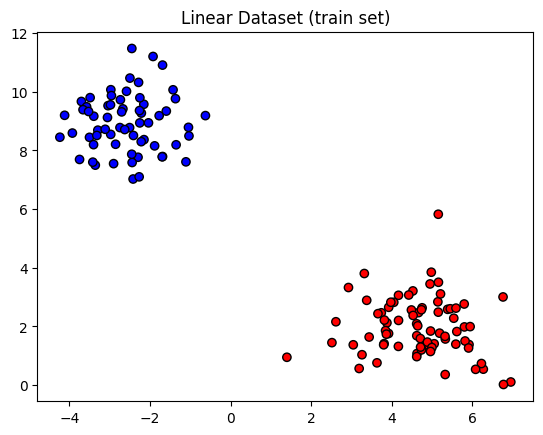

In [2]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_linear_data()

plot_data(X_train,y_train,"Linear Dataset (train set)")

In [3]:
models = [Perceptron, MLP]
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}
acc_histories = {}

for m in models:
    result = run_experiment(
        model_class=m,
        train_loader=dl_train,
        test_loader=dl_test,
        lr=0.001,
        epochs=50,
        optimizer_name=optimizer[0],
        criterion_name=criterion[0],
    	dataset_name="blob_linear",
        X_vis=X_train,
        y_vis=y_train,
        model_kwargs={}
    )

    loss_histories[f"train model={m.__name__}"] = result["train_loss"]
    loss_histories[f"test model={m.__name__}"] = result["test_loss"]
    acc_histories[f"train model={m.__name__}"] = result["train_acc"]
    acc_histories[f"test model={m.__name__}"] = result["test_acc"]


Epoch 1 | Train Acc: 28.6% | Test Acc: 45.0%
Epoch 10 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 20 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 30 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 40 | Train Acc: 90.7% | Test Acc: 98.3%
Epoch 50 | Train Acc: 100.0% | Test Acc: 100.0%
Epoch 1 | Train Acc: 52.9% | Test Acc: 38.3%
Epoch 10 | Train Acc: 53.6% | Test Acc: 38.3%
Epoch 20 | Train Acc: 53.6% | Test Acc: 38.3%
Epoch 30 | Train Acc: 55.0% | Test Acc: 38.3%
Epoch 40 | Train Acc: 55.0% | Test Acc: 38.3%
Epoch 50 | Train Acc: 55.0% | Test Acc: 38.3%


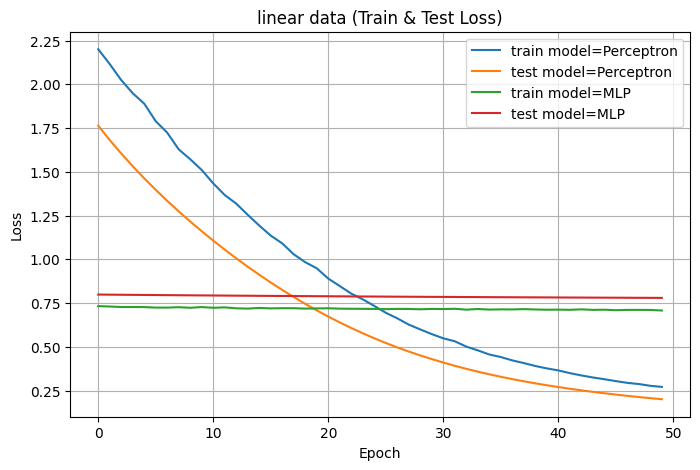

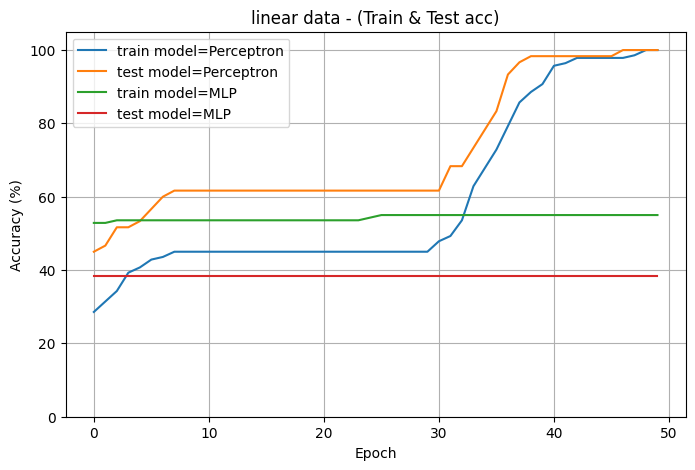

In [4]:
plot_multi_training_curves(
    loss_histories,
    "linear data (Train & Test Loss)",
    "model_comparison"
)    

plot_multi_accuracy_curves(
    acc_histories,
    "linear data - (Train & Test acc)",
    "model_comparison"
)    


ب) میانگین زمان آموزش (به میلی ثانیه) برای هر مدل را در 10 اجرای متوالی محاسبه کنید. کدام سریع تر است ؟

In [9]:
models = [Perceptron, MLP]
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]

loss_histories = {}
acc_histories = {}
for i in range(0,10):
	for m in models:
		result = run_experiment(
			model_class=m,
			train_loader=dl_train,
			test_loader=dl_test,
			lr=0.001,
			epochs=60,
			optimizer_name=optimizer[0],
			criterion_name=criterion[0],
			dataset_name="blob_linear",
			X_vis=X_train,
			y_vis=y_train,
			model_kwargs={}
		)

		loss_histories[f"train model={m.__name__}"] = result["train_loss"]
		loss_histories[f"test model={m.__name__}"] = result["test_loss"]
		acc_histories[f"train model={m.__name__}"] = result["train_acc"]
		acc_histories[f"test model={m.__name__}"] = result["test_acc"]


Epoch 1 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 10 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 20 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 30 | Train Acc: 67.9% | Test Acc: 75.0%
Epoch 40 | Train Acc: 97.1% | Test Acc: 98.3%
Epoch 50 | Train Acc: 99.3% | Test Acc: 100.0%
Epoch 60 | Train Acc: 100.0% | Test Acc: 100.0%
Epoch 1 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 10 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 20 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 30 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 40 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 50 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 60 | Train Acc: 45.0% | Test Acc: 61.7%
Epoch 1 | Train Acc: 2.1% | Test Acc: 1.7%
Epoch 10 | Train Acc: 2.1% | Test Acc: 1.7%
Epoch 20 | Train Acc: 2.9% | Test Acc: 1.7%
Epoch 30 | Train Acc: 97.9% | Test Acc: 100.0%
Epoch 40 | Train Acc: 99.3% | Test Acc: 100.0%
Epoch 50 | Train Acc: 99.3% | Test Acc: 100.0%
Epoch 60 | Train Acc: 100.0% | Test Acc: 100.0%
Epoch 1 | Train Acc: 45.0% | Test A

3-2-2 مقایسه روی داده ی غیرخطی (moons):

الف) با تنظیم بهترین ابرپارامترها برای هر مدل، حداکثر دقت آزمون قابل دستیابی را گزارش دهید.

Train shape: (140, 2)


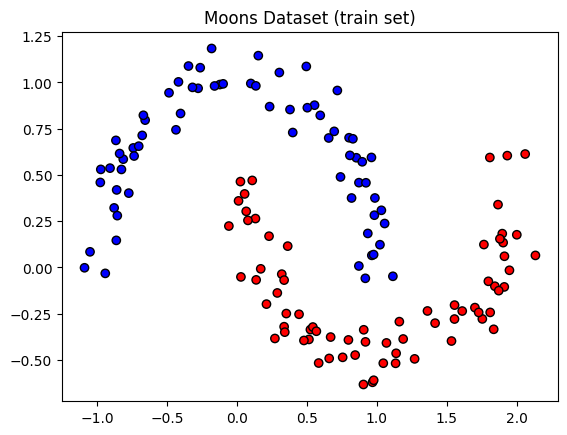

In [4]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_moons_data()

plot_data(X_train,y_train,"Moons Dataset (train set)")

Epoch 01/60 | Train Loss: 0.6788 Acc: 65.00% | Test Loss: 0.6364 Acc: 70.00%
Epoch 10/60 | Train Loss: 0.3989 Acc: 84.29% | Test Loss: 0.3516 Acc: 88.33%
Epoch 20/60 | Train Loss: 0.3441 Acc: 85.00% | Test Loss: 0.2981 Acc: 85.00%
Epoch 30/60 | Train Loss: 0.3251 Acc: 85.71% | Test Loss: 0.2790 Acc: 85.00%
Epoch 40/60 | Train Loss: 0.3197 Acc: 85.71% | Test Loss: 0.2692 Acc: 86.67%
Epoch 50/60 | Train Loss: 0.3111 Acc: 85.71% | Test Loss: 0.2636 Acc: 86.67%
Epoch 60/60 | Train Loss: 0.3019 Acc: 85.71% | Test Loss: 0.2586 Acc: 86.67%


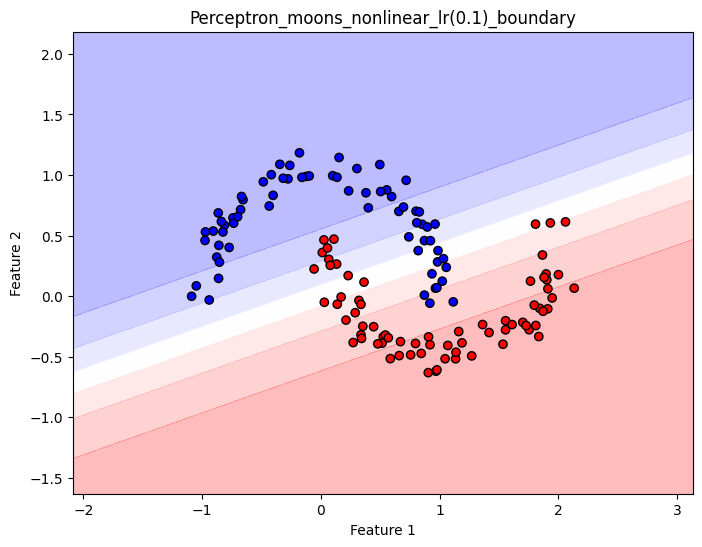

Epoch 01/100 | Train Loss: 0.6800 Acc: 63.57% | Test Loss: 0.6105 Acc: 91.67%
Epoch 10/100 | Train Loss: 0.3471 Acc: 84.29% | Test Loss: 0.2899 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.2942 Acc: 86.43% | Test Loss: 0.2453 Acc: 86.67%
Epoch 30/100 | Train Loss: 0.2808 Acc: 84.29% | Test Loss: 0.2416 Acc: 88.33%
Epoch 40/100 | Train Loss: 0.2728 Acc: 85.00% | Test Loss: 0.2300 Acc: 88.33%
Epoch 50/100 | Train Loss: 0.2703 Acc: 85.00% | Test Loss: 0.2185 Acc: 90.00%
Epoch 60/100 | Train Loss: 0.2640 Acc: 86.43% | Test Loss: 0.2168 Acc: 90.00%
Epoch 70/100 | Train Loss: 0.2555 Acc: 85.00% | Test Loss: 0.2115 Acc: 88.33%
Epoch 80/100 | Train Loss: 0.2491 Acc: 85.00% | Test Loss: 0.1972 Acc: 90.00%
Epoch 90/100 | Train Loss: 0.2422 Acc: 87.14% | Test Loss: 0.1897 Acc: 90.00%
Epoch 100/100 | Train Loss: 0.2208 Acc: 86.43% | Test Loss: 0.1823 Acc: 91.67%


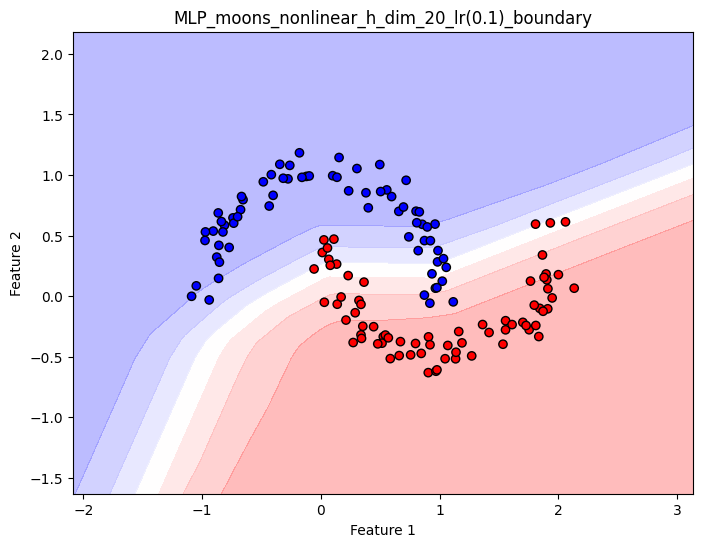

Epoch 01/100 | Train Loss: 0.7012 Acc: 48.57% | Test Loss: 0.6729 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.5111 Acc: 78.57% | Test Loss: 0.4771 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.4105 Acc: 82.86% | Test Loss: 0.3750 Acc: 83.33%
Epoch 30/100 | Train Loss: 0.3529 Acc: 85.71% | Test Loss: 0.3179 Acc: 86.67%
Epoch 40/100 | Train Loss: 0.3285 Acc: 85.00% | Test Loss: 0.2719 Acc: 88.33%
Epoch 50/100 | Train Loss: 0.3115 Acc: 85.00% | Test Loss: 0.2632 Acc: 90.00%
Epoch 60/100 | Train Loss: 0.3066 Acc: 85.71% | Test Loss: 0.2517 Acc: 90.00%
Epoch 70/100 | Train Loss: 0.3022 Acc: 85.71% | Test Loss: 0.2503 Acc: 90.00%
Epoch 80/100 | Train Loss: 0.2981 Acc: 85.71% | Test Loss: 0.2491 Acc: 90.00%
Epoch 90/100 | Train Loss: 0.2943 Acc: 85.71% | Test Loss: 0.2451 Acc: 90.00%
Epoch 100/100 | Train Loss: 0.2951 Acc: 84.29% | Test Loss: 0.2468 Acc: 88.33%


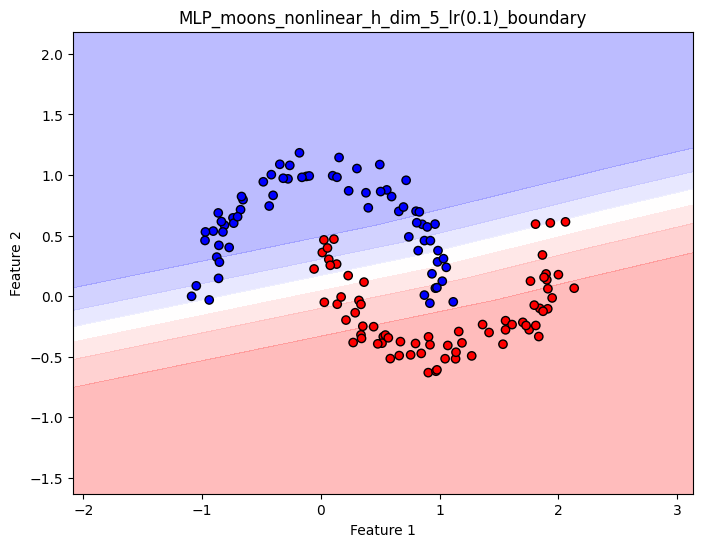

Epoch 01/100 | Train Loss: 0.7142 Acc: 48.57% | Test Loss: 0.6922 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.6936 Acc: 51.43% | Test Loss: 0.6947 Acc: 46.67%
Epoch 20/100 | Train Loss: 0.6936 Acc: 51.43% | Test Loss: 0.6948 Acc: 46.67%
Epoch 30/100 | Train Loss: 0.6935 Acc: 51.43% | Test Loss: 0.6951 Acc: 46.67%
Epoch 40/100 | Train Loss: 0.6930 Acc: 51.43% | Test Loss: 0.6955 Acc: 46.67%
Epoch 50/100 | Train Loss: 0.6939 Acc: 51.43% | Test Loss: 0.6955 Acc: 46.67%
Epoch 60/100 | Train Loss: 0.6933 Acc: 51.43% | Test Loss: 0.6958 Acc: 46.67%
Epoch 70/100 | Train Loss: 0.6942 Acc: 51.43% | Test Loss: 0.6967 Acc: 46.67%
Epoch 80/100 | Train Loss: 0.6928 Acc: 51.43% | Test Loss: 0.6958 Acc: 46.67%
Epoch 90/100 | Train Loss: 0.6933 Acc: 51.43% | Test Loss: 0.6965 Acc: 46.67%
Epoch 100/100 | Train Loss: 0.6934 Acc: 51.43% | Test Loss: 0.6958 Acc: 46.67%


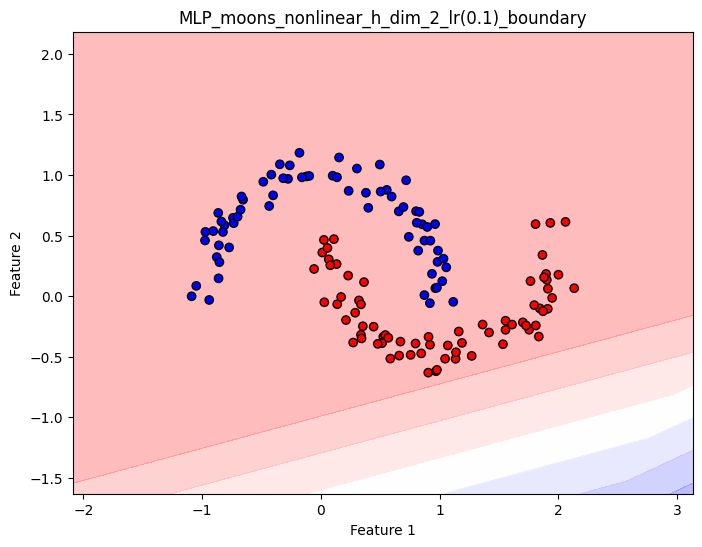

Epoch 01/100 | Train Loss: 0.5893 Acc: 80.00% | Test Loss: 0.5054 Acc: 85.00%
Epoch 10/100 | Train Loss: 0.3251 Acc: 85.71% | Test Loss: 0.2761 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.2868 Acc: 86.43% | Test Loss: 0.2443 Acc: 86.67%
Epoch 30/100 | Train Loss: 0.2662 Acc: 85.71% | Test Loss: 0.2198 Acc: 88.33%
Epoch 40/100 | Train Loss: 0.2659 Acc: 86.43% | Test Loss: 0.2142 Acc: 88.33%
Epoch 50/100 | Train Loss: 0.2397 Acc: 85.71% | Test Loss: 0.1951 Acc: 90.00%
Epoch 60/100 | Train Loss: 0.2277 Acc: 88.57% | Test Loss: 0.1799 Acc: 93.33%
Epoch 70/100 | Train Loss: 0.2099 Acc: 89.29% | Test Loss: 0.1688 Acc: 96.67%
Epoch 80/100 | Train Loss: 0.1928 Acc: 91.43% | Test Loss: 0.1597 Acc: 96.67%
Epoch 90/100 | Train Loss: 0.1755 Acc: 92.14% | Test Loss: 0.1429 Acc: 96.67%
Epoch 100/100 | Train Loss: 0.1655 Acc: 92.14% | Test Loss: 0.1347 Acc: 98.33%


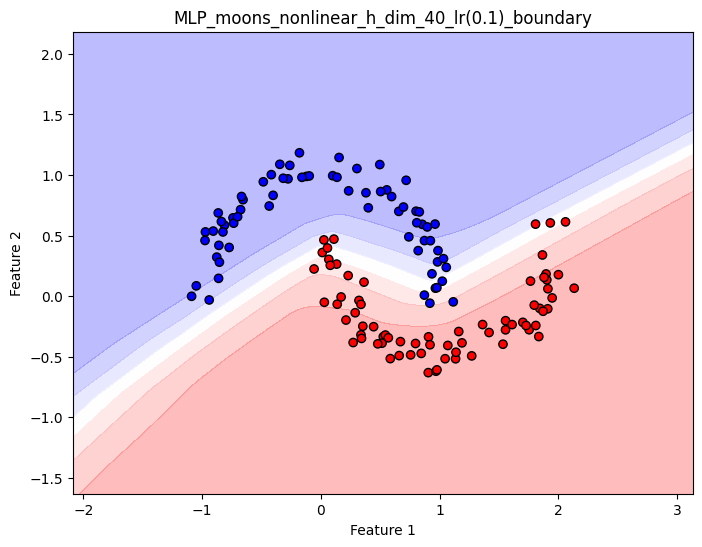

Epoch 01/60 | Train Loss: 0.6612 Acc: 61.43% | Test Loss: 0.6396 Acc: 63.33%
Epoch 10/60 | Train Loss: 0.5011 Acc: 75.00% | Test Loss: 0.4621 Acc: 76.67%
Epoch 20/60 | Train Loss: 0.4286 Acc: 78.57% | Test Loss: 0.3845 Acc: 83.33%
Epoch 30/60 | Train Loss: 0.3924 Acc: 81.43% | Test Loss: 0.3464 Acc: 83.33%
Epoch 40/60 | Train Loss: 0.3692 Acc: 81.43% | Test Loss: 0.3237 Acc: 83.33%
Epoch 50/60 | Train Loss: 0.3570 Acc: 83.57% | Test Loss: 0.3086 Acc: 83.33%
Epoch 60/60 | Train Loss: 0.3448 Acc: 84.29% | Test Loss: 0.2980 Acc: 83.33%


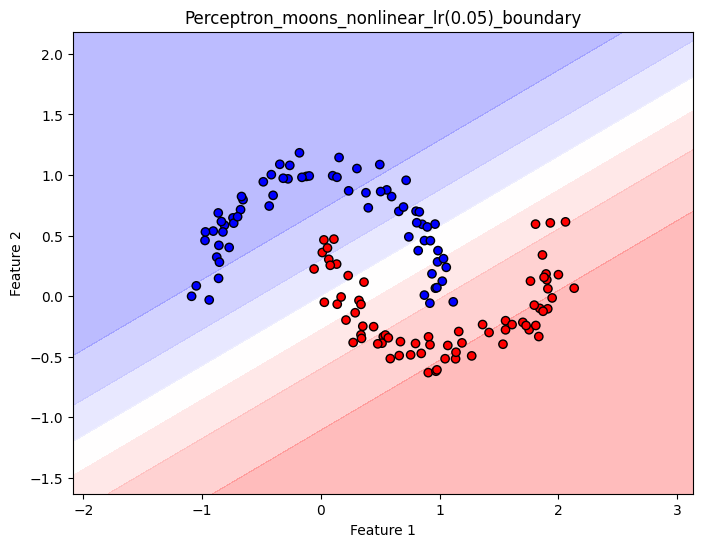

Epoch 01/100 | Train Loss: 0.6782 Acc: 52.14% | Test Loss: 0.6553 Acc: 66.67%
Epoch 10/100 | Train Loss: 0.4493 Acc: 80.71% | Test Loss: 0.4070 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.3576 Acc: 82.86% | Test Loss: 0.3164 Acc: 85.00%
Epoch 30/100 | Train Loss: 0.3185 Acc: 84.29% | Test Loss: 0.2829 Acc: 85.00%
Epoch 40/100 | Train Loss: 0.3074 Acc: 85.71% | Test Loss: 0.2661 Acc: 86.67%
Epoch 50/100 | Train Loss: 0.2851 Acc: 87.14% | Test Loss: 0.2536 Acc: 86.67%
Epoch 60/100 | Train Loss: 0.2788 Acc: 87.14% | Test Loss: 0.2430 Acc: 88.33%
Epoch 70/100 | Train Loss: 0.2653 Acc: 87.14% | Test Loss: 0.2322 Acc: 88.33%
Epoch 80/100 | Train Loss: 0.2587 Acc: 87.86% | Test Loss: 0.2248 Acc: 90.00%
Epoch 90/100 | Train Loss: 0.2455 Acc: 87.86% | Test Loss: 0.2156 Acc: 91.67%
Epoch 100/100 | Train Loss: 0.2423 Acc: 88.57% | Test Loss: 0.2098 Acc: 91.67%


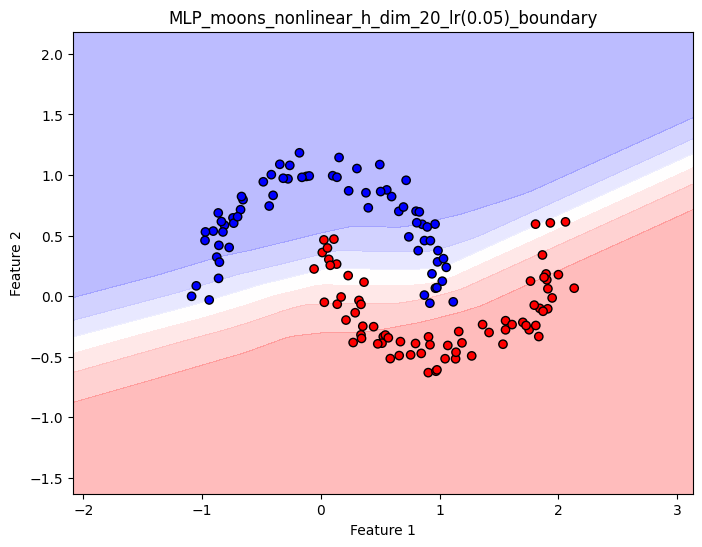

Epoch 01/100 | Train Loss: 0.6619 Acc: 48.57% | Test Loss: 0.6263 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.4683 Acc: 76.43% | Test Loss: 0.4235 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.3661 Acc: 82.14% | Test Loss: 0.3228 Acc: 83.33%
Epoch 30/100 | Train Loss: 0.3239 Acc: 85.71% | Test Loss: 0.2817 Acc: 85.00%
Epoch 40/100 | Train Loss: 0.3075 Acc: 86.43% | Test Loss: 0.2635 Acc: 86.67%
Epoch 50/100 | Train Loss: 0.2881 Acc: 86.43% | Test Loss: 0.2525 Acc: 86.67%
Epoch 60/100 | Train Loss: 0.2828 Acc: 86.43% | Test Loss: 0.2438 Acc: 88.33%
Epoch 70/100 | Train Loss: 0.2792 Acc: 86.43% | Test Loss: 0.2397 Acc: 88.33%
Epoch 80/100 | Train Loss: 0.2743 Acc: 86.43% | Test Loss: 0.2379 Acc: 88.33%
Epoch 90/100 | Train Loss: 0.2787 Acc: 85.71% | Test Loss: 0.2374 Acc: 88.33%
Epoch 100/100 | Train Loss: 0.2789 Acc: 85.71% | Test Loss: 0.2360 Acc: 88.33%


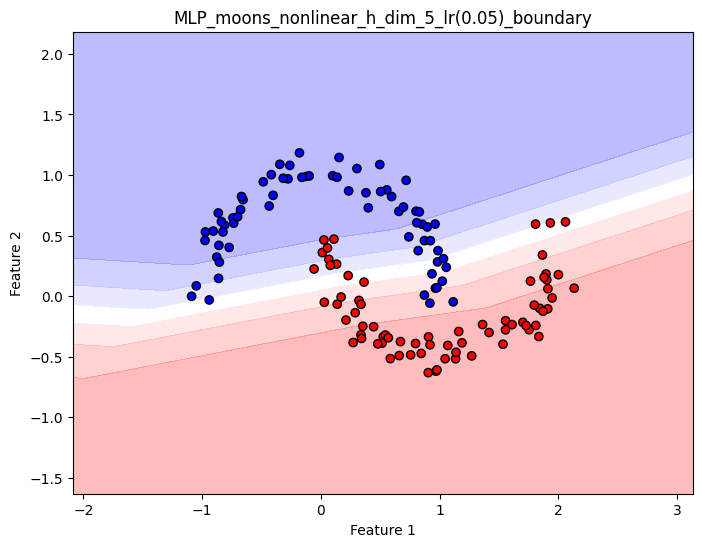

Epoch 01/100 | Train Loss: 0.6496 Acc: 66.43% | Test Loss: 0.6347 Acc: 80.00%
Epoch 10/100 | Train Loss: 0.5568 Acc: 75.00% | Test Loss: 0.5375 Acc: 76.67%
Epoch 20/100 | Train Loss: 0.4945 Acc: 77.14% | Test Loss: 0.4604 Acc: 83.33%
Epoch 30/100 | Train Loss: 0.4420 Acc: 80.00% | Test Loss: 0.4077 Acc: 83.33%
Epoch 40/100 | Train Loss: 0.4048 Acc: 82.86% | Test Loss: 0.3721 Acc: 83.33%
Epoch 50/100 | Train Loss: 0.3757 Acc: 85.71% | Test Loss: 0.3409 Acc: 83.33%
Epoch 60/100 | Train Loss: 0.3486 Acc: 85.71% | Test Loss: 0.3106 Acc: 85.00%
Epoch 70/100 | Train Loss: 0.3361 Acc: 85.71% | Test Loss: 0.2912 Acc: 88.33%
Epoch 80/100 | Train Loss: 0.3310 Acc: 86.43% | Test Loss: 0.2781 Acc: 88.33%
Epoch 90/100 | Train Loss: 0.3184 Acc: 85.00% | Test Loss: 0.2722 Acc: 88.33%
Epoch 100/100 | Train Loss: 0.3186 Acc: 85.00% | Test Loss: 0.2632 Acc: 90.00%


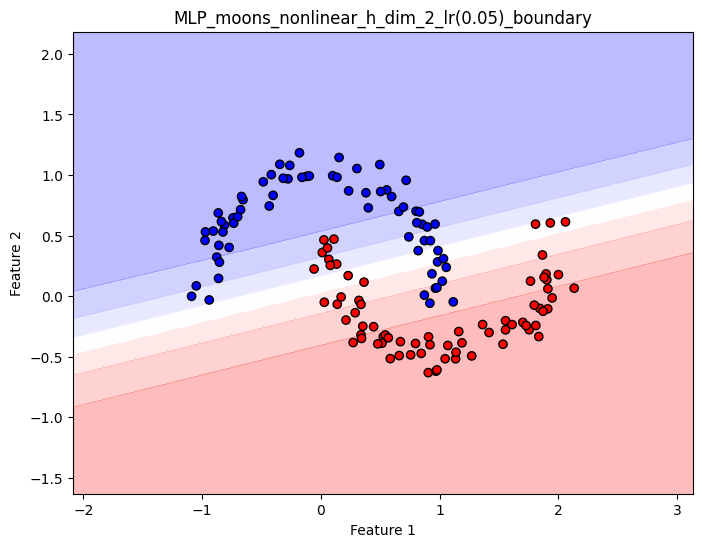

Epoch 01/100 | Train Loss: 0.6605 Acc: 65.00% | Test Loss: 0.6096 Acc: 81.67%
Epoch 10/100 | Train Loss: 0.3775 Acc: 84.29% | Test Loss: 0.3264 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.3186 Acc: 85.71% | Test Loss: 0.2744 Acc: 85.00%
Epoch 30/100 | Train Loss: 0.2953 Acc: 86.43% | Test Loss: 0.2541 Acc: 86.67%
Epoch 40/100 | Train Loss: 0.2825 Acc: 85.00% | Test Loss: 0.2409 Acc: 88.33%
Epoch 50/100 | Train Loss: 0.2768 Acc: 85.00% | Test Loss: 0.2283 Acc: 88.33%
Epoch 60/100 | Train Loss: 0.2669 Acc: 84.29% | Test Loss: 0.2243 Acc: 88.33%
Epoch 70/100 | Train Loss: 0.2681 Acc: 85.71% | Test Loss: 0.2177 Acc: 90.00%
Epoch 80/100 | Train Loss: 0.2621 Acc: 86.43% | Test Loss: 0.2148 Acc: 90.00%
Epoch 90/100 | Train Loss: 0.2519 Acc: 85.71% | Test Loss: 0.2065 Acc: 90.00%
Epoch 100/100 | Train Loss: 0.2549 Acc: 86.43% | Test Loss: 0.2061 Acc: 90.00%


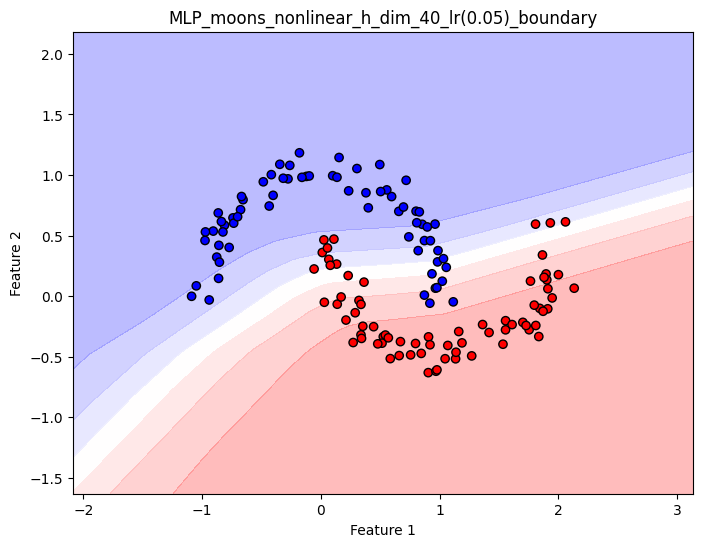

Epoch 01/60 | Train Loss: 0.6836 Acc: 63.57% | Test Loss: 0.6848 Acc: 61.67%
Epoch 10/60 | Train Loss: 0.6310 Acc: 68.57% | Test Loss: 0.6245 Acc: 65.00%
Epoch 20/60 | Train Loss: 0.5891 Acc: 74.29% | Test Loss: 0.5718 Acc: 70.00%
Epoch 30/60 | Train Loss: 0.5536 Acc: 71.43% | Test Loss: 0.5306 Acc: 73.33%
Epoch 40/60 | Train Loss: 0.5300 Acc: 72.14% | Test Loss: 0.4977 Acc: 76.67%
Epoch 50/60 | Train Loss: 0.5079 Acc: 74.29% | Test Loss: 0.4710 Acc: 76.67%
Epoch 60/60 | Train Loss: 0.4844 Acc: 74.29% | Test Loss: 0.4492 Acc: 76.67%


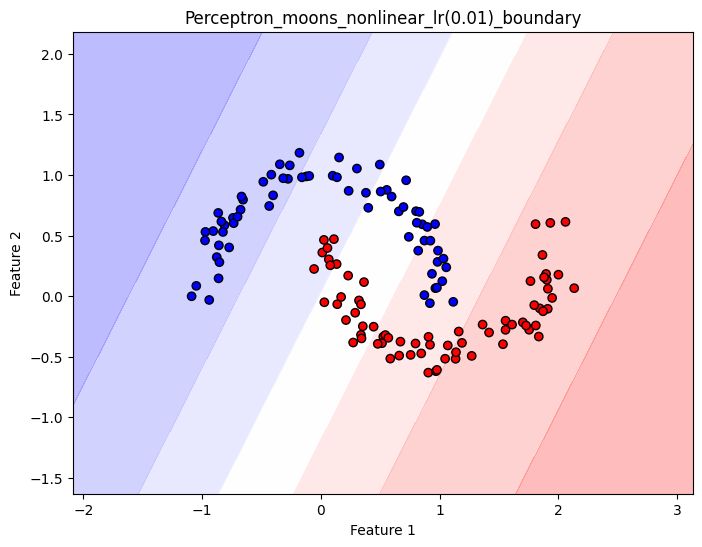

Epoch 01/100 | Train Loss: 0.7551 Acc: 48.57% | Test Loss: 0.7242 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.6393 Acc: 57.14% | Test Loss: 0.6195 Acc: 66.67%
Epoch 20/100 | Train Loss: 0.5675 Acc: 82.14% | Test Loss: 0.5451 Acc: 83.33%
Epoch 30/100 | Train Loss: 0.5152 Acc: 80.00% | Test Loss: 0.4860 Acc: 83.33%
Epoch 40/100 | Train Loss: 0.4721 Acc: 79.29% | Test Loss: 0.4380 Acc: 83.33%
Epoch 50/100 | Train Loss: 0.4407 Acc: 80.71% | Test Loss: 0.4007 Acc: 83.33%
Epoch 60/100 | Train Loss: 0.4164 Acc: 81.43% | Test Loss: 0.3721 Acc: 83.33%
Epoch 70/100 | Train Loss: 0.3903 Acc: 82.14% | Test Loss: 0.3497 Acc: 83.33%
Epoch 80/100 | Train Loss: 0.3724 Acc: 82.86% | Test Loss: 0.3321 Acc: 83.33%
Epoch 90/100 | Train Loss: 0.3657 Acc: 83.57% | Test Loss: 0.3184 Acc: 83.33%
Epoch 100/100 | Train Loss: 0.3535 Acc: 83.57% | Test Loss: 0.3070 Acc: 83.33%


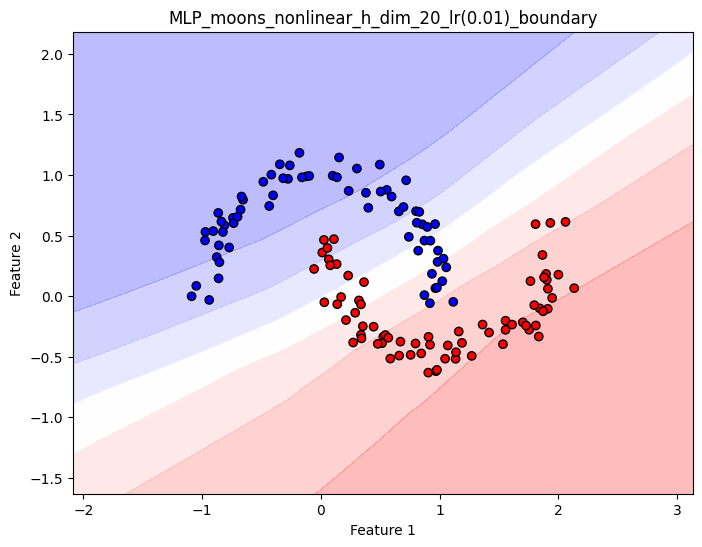

Epoch 01/100 | Train Loss: 0.6682 Acc: 52.14% | Test Loss: 0.6633 Acc: 51.67%
Epoch 10/100 | Train Loss: 0.6504 Acc: 60.71% | Test Loss: 0.6463 Acc: 55.00%
Epoch 20/100 | Train Loss: 0.6332 Acc: 67.86% | Test Loss: 0.6270 Acc: 61.67%
Epoch 30/100 | Train Loss: 0.6144 Acc: 69.29% | Test Loss: 0.6073 Acc: 63.33%
Epoch 40/100 | Train Loss: 0.5966 Acc: 70.71% | Test Loss: 0.5867 Acc: 68.33%
Epoch 50/100 | Train Loss: 0.5840 Acc: 71.43% | Test Loss: 0.5655 Acc: 71.67%
Epoch 60/100 | Train Loss: 0.5627 Acc: 72.14% | Test Loss: 0.5451 Acc: 73.33%
Epoch 70/100 | Train Loss: 0.5510 Acc: 72.86% | Test Loss: 0.5255 Acc: 76.67%
Epoch 80/100 | Train Loss: 0.5388 Acc: 74.29% | Test Loss: 0.5068 Acc: 76.67%
Epoch 90/100 | Train Loss: 0.5234 Acc: 75.00% | Test Loss: 0.4898 Acc: 76.67%
Epoch 100/100 | Train Loss: 0.5073 Acc: 75.71% | Test Loss: 0.4736 Acc: 78.33%


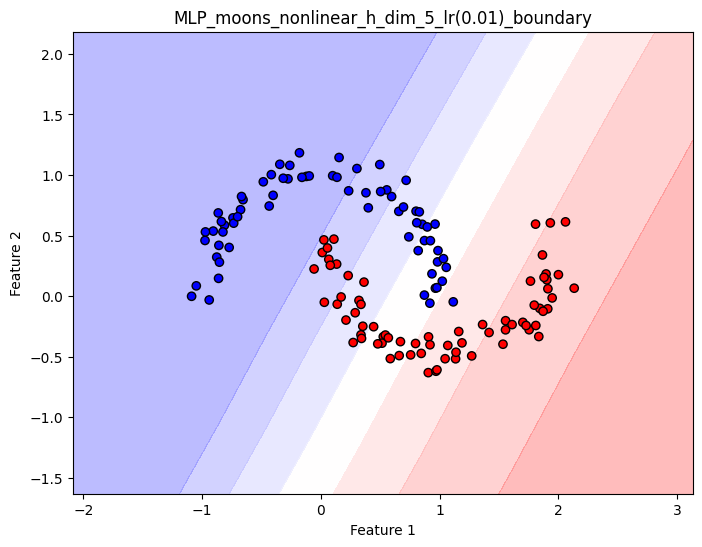

Epoch 01/100 | Train Loss: 0.6949 Acc: 51.43% | Test Loss: 0.7050 Acc: 46.67%
Epoch 10/100 | Train Loss: 0.6947 Acc: 51.43% | Test Loss: 0.7029 Acc: 46.67%
Epoch 20/100 | Train Loss: 0.6941 Acc: 51.43% | Test Loss: 0.7013 Acc: 46.67%
Epoch 30/100 | Train Loss: 0.6931 Acc: 51.43% | Test Loss: 0.6999 Acc: 46.67%
Epoch 40/100 | Train Loss: 0.6929 Acc: 51.43% | Test Loss: 0.6992 Acc: 46.67%
Epoch 50/100 | Train Loss: 0.6930 Acc: 51.43% | Test Loss: 0.6985 Acc: 46.67%
Epoch 60/100 | Train Loss: 0.6927 Acc: 51.43% | Test Loss: 0.6979 Acc: 46.67%
Epoch 70/100 | Train Loss: 0.6924 Acc: 51.43% | Test Loss: 0.6976 Acc: 46.67%
Epoch 80/100 | Train Loss: 0.6924 Acc: 51.43% | Test Loss: 0.6973 Acc: 46.67%
Epoch 90/100 | Train Loss: 0.6930 Acc: 51.43% | Test Loss: 0.6970 Acc: 46.67%
Epoch 100/100 | Train Loss: 0.6922 Acc: 51.43% | Test Loss: 0.6969 Acc: 46.67%


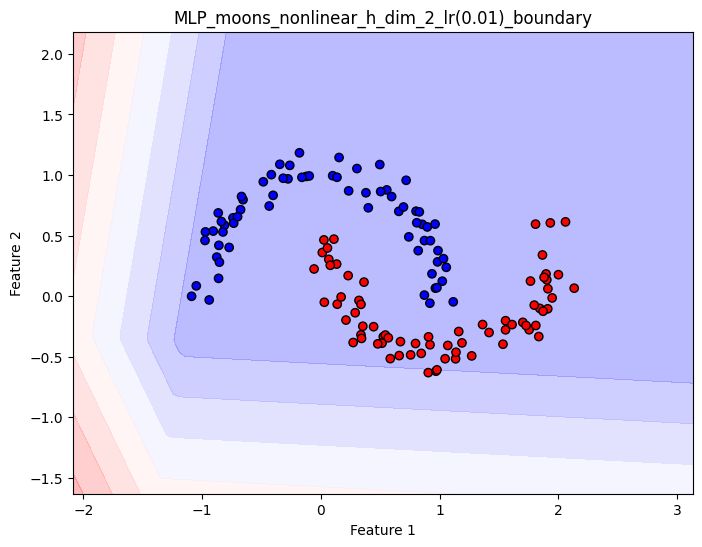

Epoch 01/100 | Train Loss: 0.7212 Acc: 36.43% | Test Loss: 0.7156 Acc: 50.00%
Epoch 10/100 | Train Loss: 0.6059 Acc: 79.29% | Test Loss: 0.5895 Acc: 85.00%
Epoch 20/100 | Train Loss: 0.5240 Acc: 80.71% | Test Loss: 0.4966 Acc: 85.00%
Epoch 30/100 | Train Loss: 0.4733 Acc: 80.71% | Test Loss: 0.4328 Acc: 83.33%
Epoch 40/100 | Train Loss: 0.4337 Acc: 82.14% | Test Loss: 0.3877 Acc: 83.33%
Epoch 50/100 | Train Loss: 0.3982 Acc: 83.57% | Test Loss: 0.3551 Acc: 83.33%
Epoch 60/100 | Train Loss: 0.3739 Acc: 83.57% | Test Loss: 0.3307 Acc: 83.33%
Epoch 70/100 | Train Loss: 0.3623 Acc: 84.29% | Test Loss: 0.3124 Acc: 83.33%
Epoch 80/100 | Train Loss: 0.3448 Acc: 85.00% | Test Loss: 0.2988 Acc: 83.33%
Epoch 90/100 | Train Loss: 0.3386 Acc: 85.00% | Test Loss: 0.2877 Acc: 83.33%
Epoch 100/100 | Train Loss: 0.3222 Acc: 85.71% | Test Loss: 0.2785 Acc: 83.33%


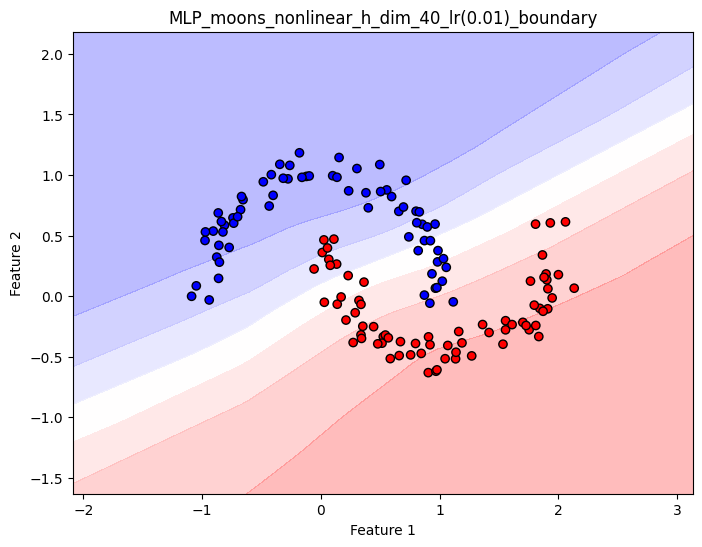

Epoch 01/60 | Train Loss: 0.8140 Acc: 40.71% | Test Loss: 0.7947 Acc: 40.00%
Epoch 10/60 | Train Loss: 0.7357 Acc: 44.29% | Test Loss: 0.7204 Acc: 46.67%
Epoch 20/60 | Train Loss: 0.6656 Acc: 58.57% | Test Loss: 0.6540 Acc: 56.67%
Epoch 30/60 | Train Loss: 0.6162 Acc: 69.29% | Test Loss: 0.6011 Acc: 70.00%
Epoch 40/60 | Train Loss: 0.5759 Acc: 79.29% | Test Loss: 0.5592 Acc: 73.33%
Epoch 50/60 | Train Loss: 0.5457 Acc: 82.14% | Test Loss: 0.5256 Acc: 83.33%
Epoch 60/60 | Train Loss: 0.5189 Acc: 85.71% | Test Loss: 0.4984 Acc: 86.67%


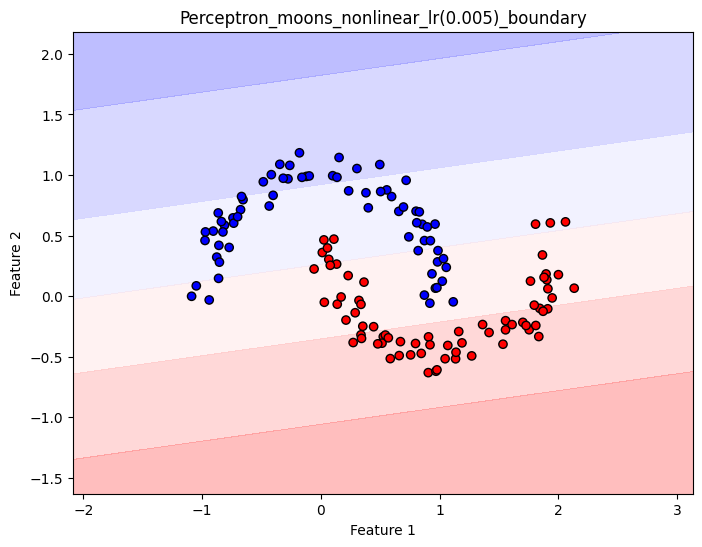

Epoch 01/100 | Train Loss: 0.6718 Acc: 72.86% | Test Loss: 0.6681 Acc: 75.00%
Epoch 10/100 | Train Loss: 0.6303 Acc: 74.29% | Test Loss: 0.6211 Acc: 76.67%
Epoch 20/100 | Train Loss: 0.5913 Acc: 75.00% | Test Loss: 0.5772 Acc: 76.67%
Epoch 30/100 | Train Loss: 0.5587 Acc: 76.43% | Test Loss: 0.5395 Acc: 80.00%
Epoch 40/100 | Train Loss: 0.5337 Acc: 76.43% | Test Loss: 0.5073 Acc: 83.33%
Epoch 50/100 | Train Loss: 0.5088 Acc: 77.14% | Test Loss: 0.4792 Acc: 83.33%
Epoch 60/100 | Train Loss: 0.4882 Acc: 77.14% | Test Loss: 0.4549 Acc: 83.33%
Epoch 70/100 | Train Loss: 0.4699 Acc: 77.86% | Test Loss: 0.4339 Acc: 83.33%
Epoch 80/100 | Train Loss: 0.4515 Acc: 79.29% | Test Loss: 0.4154 Acc: 83.33%
Epoch 90/100 | Train Loss: 0.4432 Acc: 80.00% | Test Loss: 0.3994 Acc: 83.33%
Epoch 100/100 | Train Loss: 0.4290 Acc: 80.71% | Test Loss: 0.3854 Acc: 83.33%


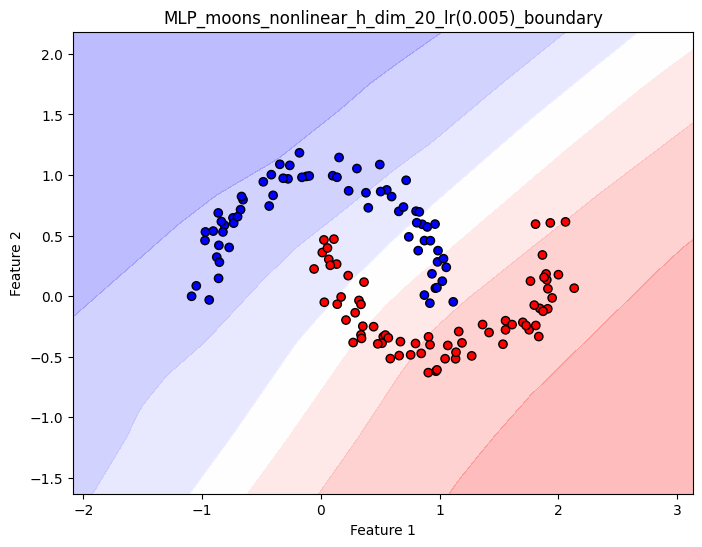

Epoch 01/100 | Train Loss: 0.7282 Acc: 42.86% | Test Loss: 0.7347 Acc: 36.67%
Epoch 10/100 | Train Loss: 0.7159 Acc: 42.86% | Test Loss: 0.7252 Acc: 30.00%
Epoch 20/100 | Train Loss: 0.7056 Acc: 42.86% | Test Loss: 0.7160 Acc: 38.33%
Epoch 30/100 | Train Loss: 0.6995 Acc: 51.43% | Test Loss: 0.7076 Acc: 46.67%
Epoch 40/100 | Train Loss: 0.6892 Acc: 51.43% | Test Loss: 0.6995 Acc: 46.67%
Epoch 50/100 | Train Loss: 0.6832 Acc: 51.43% | Test Loss: 0.6914 Acc: 46.67%
Epoch 60/100 | Train Loss: 0.6755 Acc: 52.86% | Test Loss: 0.6830 Acc: 50.00%
Epoch 70/100 | Train Loss: 0.6678 Acc: 56.43% | Test Loss: 0.6741 Acc: 55.00%
Epoch 80/100 | Train Loss: 0.6570 Acc: 60.00% | Test Loss: 0.6647 Acc: 58.33%
Epoch 90/100 | Train Loss: 0.6491 Acc: 61.43% | Test Loss: 0.6547 Acc: 63.33%
Epoch 100/100 | Train Loss: 0.6401 Acc: 62.86% | Test Loss: 0.6440 Acc: 66.67%


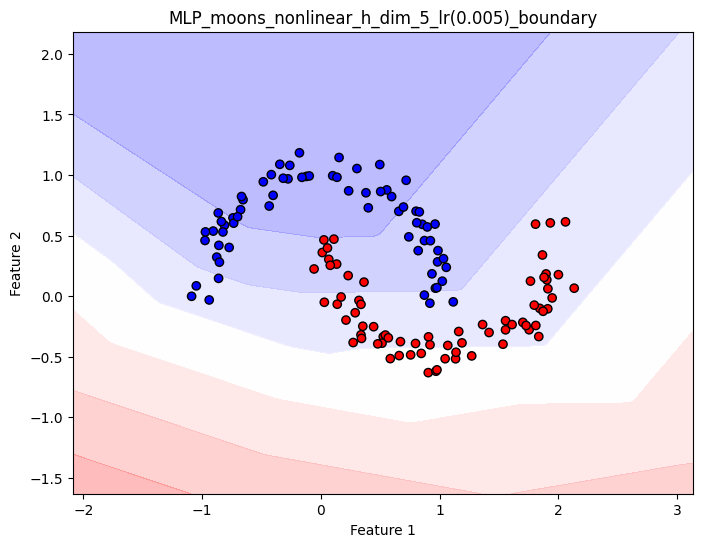

Epoch 01/100 | Train Loss: 0.7175 Acc: 48.57% | Test Loss: 0.7081 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.7087 Acc: 48.57% | Test Loss: 0.6998 Acc: 53.33%
Epoch 20/100 | Train Loss: 0.7030 Acc: 48.57% | Test Loss: 0.6948 Acc: 53.33%
Epoch 30/100 | Train Loss: 0.6995 Acc: 48.57% | Test Loss: 0.6921 Acc: 53.33%
Epoch 40/100 | Train Loss: 0.6981 Acc: 48.57% | Test Loss: 0.6912 Acc: 53.33%
Epoch 50/100 | Train Loss: 0.6964 Acc: 48.57% | Test Loss: 0.6911 Acc: 53.33%
Epoch 60/100 | Train Loss: 0.6960 Acc: 48.57% | Test Loss: 0.6911 Acc: 53.33%
Epoch 70/100 | Train Loss: 0.6949 Acc: 48.57% | Test Loss: 0.6913 Acc: 53.33%
Epoch 80/100 | Train Loss: 0.6949 Acc: 48.57% | Test Loss: 0.6915 Acc: 53.33%
Epoch 90/100 | Train Loss: 0.6944 Acc: 48.57% | Test Loss: 0.6918 Acc: 53.33%
Epoch 100/100 | Train Loss: 0.6941 Acc: 48.57% | Test Loss: 0.6920 Acc: 53.33%


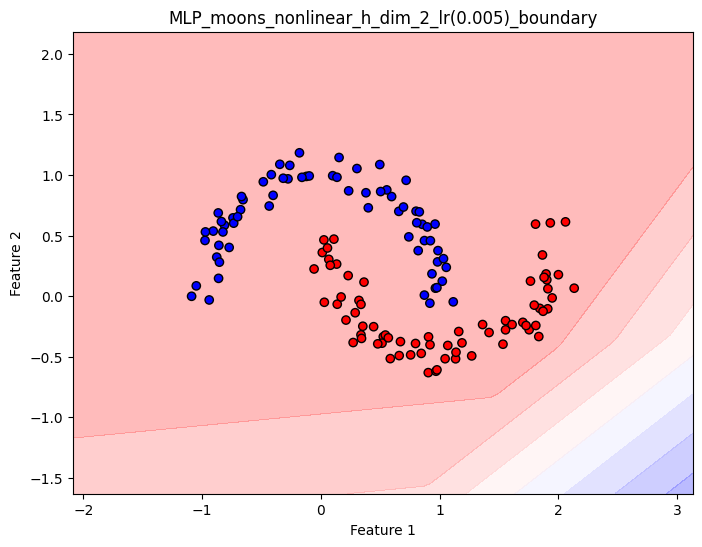

Epoch 01/100 | Train Loss: 0.6705 Acc: 62.14% | Test Loss: 0.6668 Acc: 61.67%
Epoch 10/100 | Train Loss: 0.6009 Acc: 75.71% | Test Loss: 0.5962 Acc: 78.33%
Epoch 20/100 | Train Loss: 0.5615 Acc: 79.29% | Test Loss: 0.5406 Acc: 85.00%
Epoch 30/100 | Train Loss: 0.5187 Acc: 83.57% | Test Loss: 0.4953 Acc: 86.67%
Epoch 40/100 | Train Loss: 0.4853 Acc: 82.86% | Test Loss: 0.4575 Acc: 91.67%
Epoch 50/100 | Train Loss: 0.4560 Acc: 82.86% | Test Loss: 0.4256 Acc: 93.33%
Epoch 60/100 | Train Loss: 0.4349 Acc: 82.14% | Test Loss: 0.3989 Acc: 91.67%
Epoch 70/100 | Train Loss: 0.4137 Acc: 82.86% | Test Loss: 0.3765 Acc: 90.00%
Epoch 80/100 | Train Loss: 0.4014 Acc: 83.57% | Test Loss: 0.3576 Acc: 88.33%
Epoch 90/100 | Train Loss: 0.3849 Acc: 84.29% | Test Loss: 0.3415 Acc: 88.33%
Epoch 100/100 | Train Loss: 0.3731 Acc: 84.29% | Test Loss: 0.3279 Acc: 88.33%


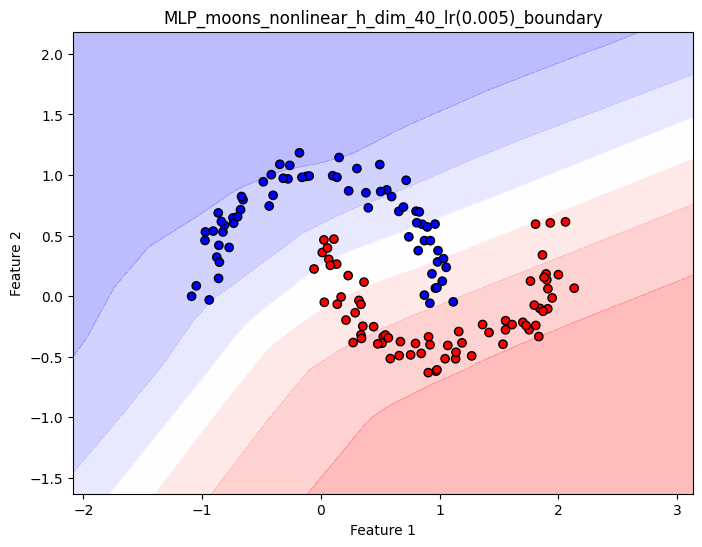

Epoch 01/60 | Train Loss: 0.5238 Acc: 80.71% | Test Loss: 0.5016 Acc: 91.67%
Epoch 10/60 | Train Loss: 0.5191 Acc: 81.43% | Test Loss: 0.4983 Acc: 91.67%
Epoch 20/60 | Train Loss: 0.5184 Acc: 81.43% | Test Loss: 0.4947 Acc: 91.67%
Epoch 30/60 | Train Loss: 0.5144 Acc: 81.43% | Test Loss: 0.4911 Acc: 90.00%
Epoch 40/60 | Train Loss: 0.5075 Acc: 80.71% | Test Loss: 0.4877 Acc: 90.00%
Epoch 50/60 | Train Loss: 0.5067 Acc: 80.71% | Test Loss: 0.4843 Acc: 90.00%
Epoch 60/60 | Train Loss: 0.5075 Acc: 81.43% | Test Loss: 0.4810 Acc: 88.33%


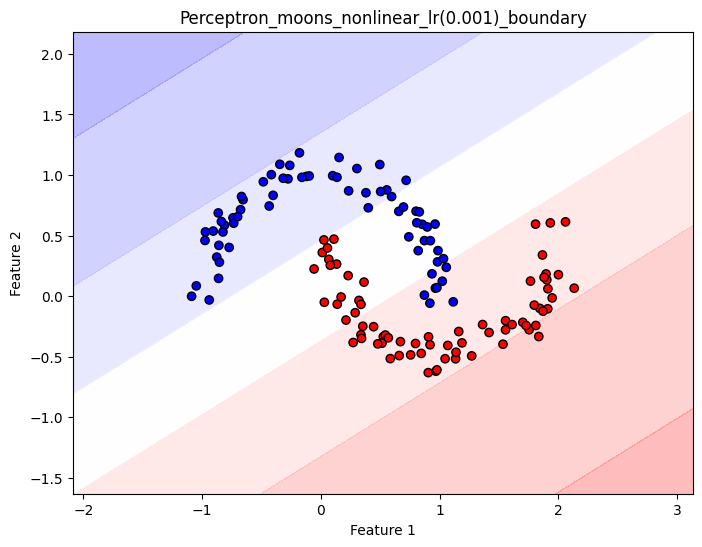

Epoch 01/100 | Train Loss: 0.7368 Acc: 43.57% | Test Loss: 0.7414 Acc: 43.33%
Epoch 10/100 | Train Loss: 0.7253 Acc: 47.14% | Test Loss: 0.7304 Acc: 46.67%
Epoch 20/100 | Train Loss: 0.7163 Acc: 50.00% | Test Loss: 0.7188 Acc: 48.33%
Epoch 30/100 | Train Loss: 0.7068 Acc: 52.14% | Test Loss: 0.7077 Acc: 53.33%
Epoch 40/100 | Train Loss: 0.6987 Acc: 61.43% | Test Loss: 0.6970 Acc: 58.33%
Epoch 50/100 | Train Loss: 0.6893 Acc: 63.57% | Test Loss: 0.6869 Acc: 61.67%
Epoch 60/100 | Train Loss: 0.6801 Acc: 66.43% | Test Loss: 0.6770 Acc: 65.00%
Epoch 70/100 | Train Loss: 0.6717 Acc: 69.29% | Test Loss: 0.6675 Acc: 65.00%
Epoch 80/100 | Train Loss: 0.6631 Acc: 70.00% | Test Loss: 0.6584 Acc: 66.67%
Epoch 90/100 | Train Loss: 0.6556 Acc: 70.00% | Test Loss: 0.6495 Acc: 70.00%
Epoch 100/100 | Train Loss: 0.6473 Acc: 72.14% | Test Loss: 0.6409 Acc: 71.67%


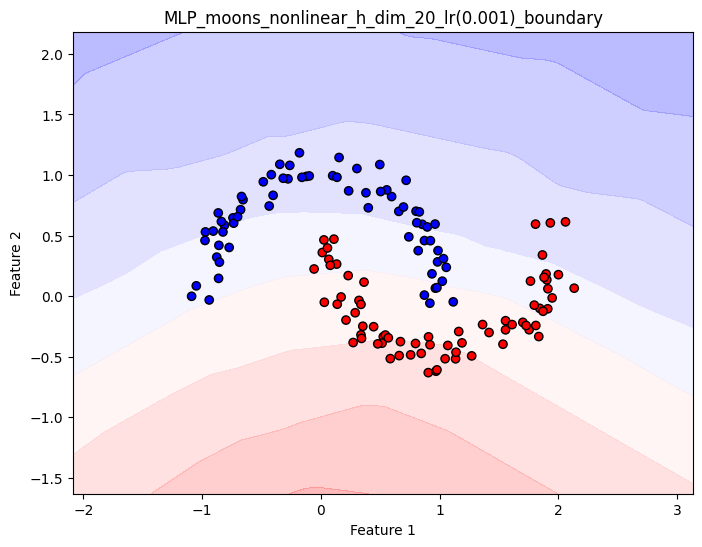

Epoch 01/100 | Train Loss: 0.6799 Acc: 51.43% | Test Loss: 0.6956 Acc: 46.67%
Epoch 10/100 | Train Loss: 0.6783 Acc: 51.43% | Test Loss: 0.6924 Acc: 46.67%
Epoch 20/100 | Train Loss: 0.6746 Acc: 51.43% | Test Loss: 0.6890 Acc: 46.67%
Epoch 30/100 | Train Loss: 0.6721 Acc: 51.43% | Test Loss: 0.6856 Acc: 46.67%
Epoch 40/100 | Train Loss: 0.6699 Acc: 51.43% | Test Loss: 0.6823 Acc: 46.67%
Epoch 50/100 | Train Loss: 0.6701 Acc: 51.43% | Test Loss: 0.6790 Acc: 46.67%
Epoch 60/100 | Train Loss: 0.6657 Acc: 51.43% | Test Loss: 0.6759 Acc: 46.67%
Epoch 70/100 | Train Loss: 0.6629 Acc: 51.43% | Test Loss: 0.6729 Acc: 46.67%
Epoch 80/100 | Train Loss: 0.6616 Acc: 51.43% | Test Loss: 0.6698 Acc: 46.67%
Epoch 90/100 | Train Loss: 0.6621 Acc: 51.43% | Test Loss: 0.6668 Acc: 46.67%
Epoch 100/100 | Train Loss: 0.6576 Acc: 51.43% | Test Loss: 0.6639 Acc: 46.67%


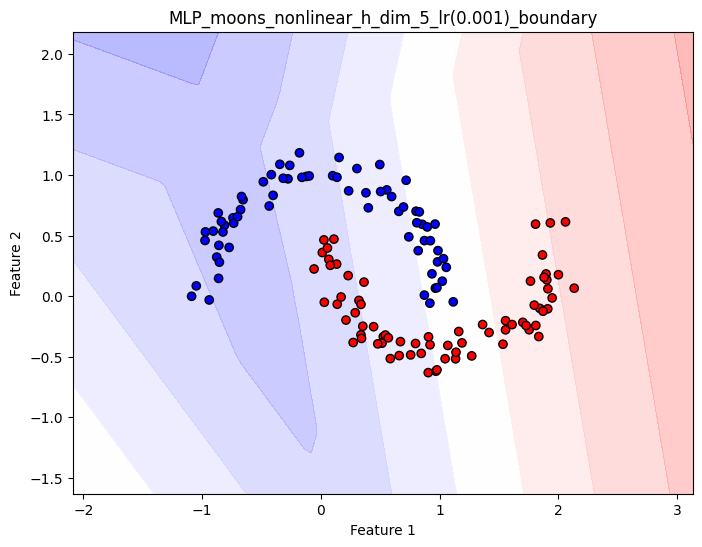

Epoch 01/100 | Train Loss: 0.7237 Acc: 51.43% | Test Loss: 0.7501 Acc: 46.67%
Epoch 10/100 | Train Loss: 0.7208 Acc: 51.43% | Test Loss: 0.7436 Acc: 46.67%
Epoch 20/100 | Train Loss: 0.7107 Acc: 51.43% | Test Loss: 0.7369 Acc: 46.67%
Epoch 30/100 | Train Loss: 0.7048 Acc: 51.43% | Test Loss: 0.7305 Acc: 46.67%
Epoch 40/100 | Train Loss: 0.6970 Acc: 51.43% | Test Loss: 0.7245 Acc: 46.67%
Epoch 50/100 | Train Loss: 0.6988 Acc: 51.43% | Test Loss: 0.7189 Acc: 46.67%
Epoch 60/100 | Train Loss: 0.6937 Acc: 51.43% | Test Loss: 0.7136 Acc: 46.67%
Epoch 70/100 | Train Loss: 0.6897 Acc: 51.43% | Test Loss: 0.7085 Acc: 46.67%
Epoch 80/100 | Train Loss: 0.6844 Acc: 51.43% | Test Loss: 0.7037 Acc: 46.67%
Epoch 90/100 | Train Loss: 0.6808 Acc: 51.43% | Test Loss: 0.6991 Acc: 46.67%
Epoch 100/100 | Train Loss: 0.6836 Acc: 51.43% | Test Loss: 0.6948 Acc: 46.67%


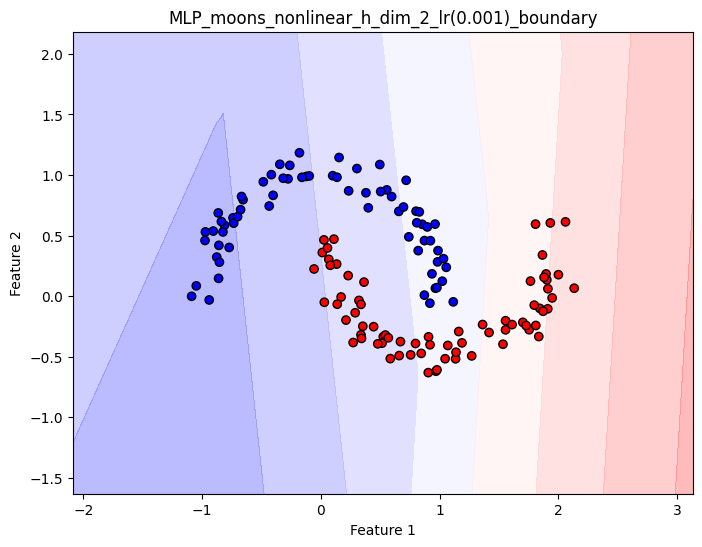

Epoch 01/100 | Train Loss: 0.7188 Acc: 48.57% | Test Loss: 0.7079 Acc: 53.33%
Epoch 10/100 | Train Loss: 0.6976 Acc: 48.57% | Test Loss: 0.6852 Acc: 53.33%
Epoch 20/100 | Train Loss: 0.6744 Acc: 49.29% | Test Loss: 0.6618 Acc: 55.00%
Epoch 30/100 | Train Loss: 0.6546 Acc: 57.86% | Test Loss: 0.6401 Acc: 60.00%
Epoch 40/100 | Train Loss: 0.6354 Acc: 67.86% | Test Loss: 0.6201 Acc: 63.33%
Epoch 50/100 | Train Loss: 0.6183 Acc: 75.71% | Test Loss: 0.6014 Acc: 71.67%
Epoch 60/100 | Train Loss: 0.6005 Acc: 82.14% | Test Loss: 0.5841 Acc: 76.67%
Epoch 70/100 | Train Loss: 0.5861 Acc: 85.00% | Test Loss: 0.5680 Acc: 83.33%
Epoch 80/100 | Train Loss: 0.5723 Acc: 85.00% | Test Loss: 0.5529 Acc: 86.67%
Epoch 90/100 | Train Loss: 0.5598 Acc: 84.29% | Test Loss: 0.5387 Acc: 85.00%
Epoch 100/100 | Train Loss: 0.5467 Acc: 85.71% | Test Loss: 0.5254 Acc: 86.67%


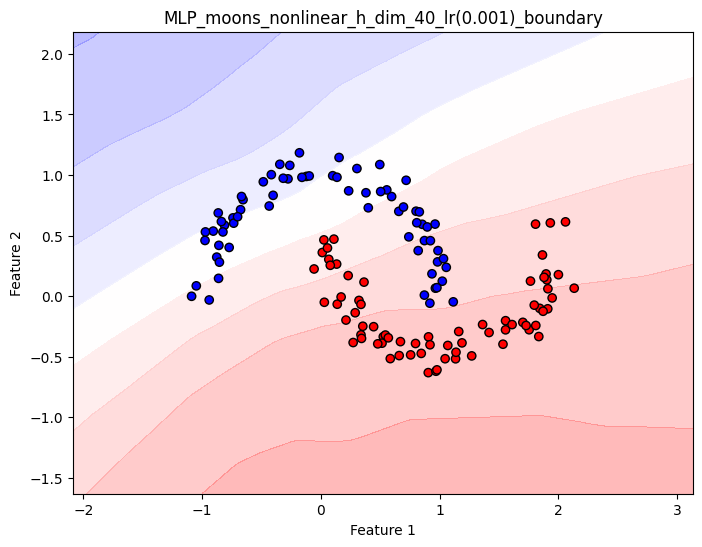

In [9]:
models = [Perceptron, MLP]
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
learning_rates = [0.1,0.05,0.01,0.005,0.001]
hidden_dims_lists = [20,5,2,40]

loss_histories = {}
acc_histories = {}
for lr in learning_rates:
	for m in models:
		if m == MLP:
			for h_dim in hidden_dims_lists:
				result = run_experiment(
					model_class=m,
					train_loader=dl_train,
					test_loader=dl_test,
					lr=lr,
					epochs=100,
					optimizer_name=optimizer[0],
					criterion_name=criterion[0],
					dataset_name=f"moons_nonlinear_h_dim_{h_dim}",
					plot_decision=True,
					X_vis=X_train,
					y_vis=y_train,
					model_kwargs={"hidden_dim": h_dim, "output_dim": 1}
				)

				loss_histories[f"train model={m.__name__} lr={lr}_h{h_dim}"] = result["train_loss"]
				loss_histories[f"test model={m.__name__} lr={lr}_h{h_dim}"] = result["test_loss"]
				acc_histories[f"train model={m.__name__} lr={lr}_h{h_dim}"] = result["train_acc"]
				acc_histories[f"test model={m.__name__} lr={lr}_h{h_dim}"] = result["test_acc"]
		else:
			result = run_experiment(
					model_class=m,
					train_loader=dl_train,
					test_loader=dl_test,
					lr=lr,
					epochs=60,
					optimizer_name=optimizer[0],
					criterion_name=criterion[0],
					dataset_name="moons_nonlinear",
					plot_decision=True,
					X_vis=X_train,
					y_vis=y_train,
					model_kwargs={}
				)

			loss_histories[f"train model={m.__name__} lr={lr}"] = result["train_loss"]
			loss_histories[f"test model={m.__name__} lr={lr}"] = result["test_loss"]
			acc_histories[f"train model={m.__name__} lr={lr}"] = result["train_acc"]
			acc_histories[f"test model={m.__name__} lr={lr}"] = result["test_acc"]

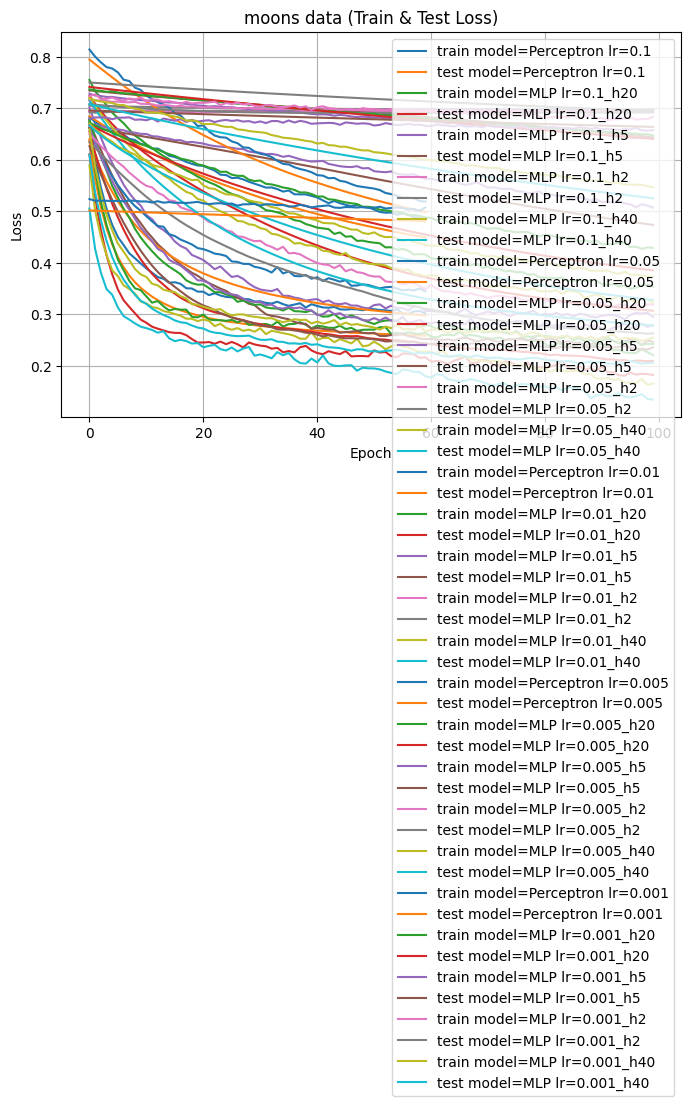

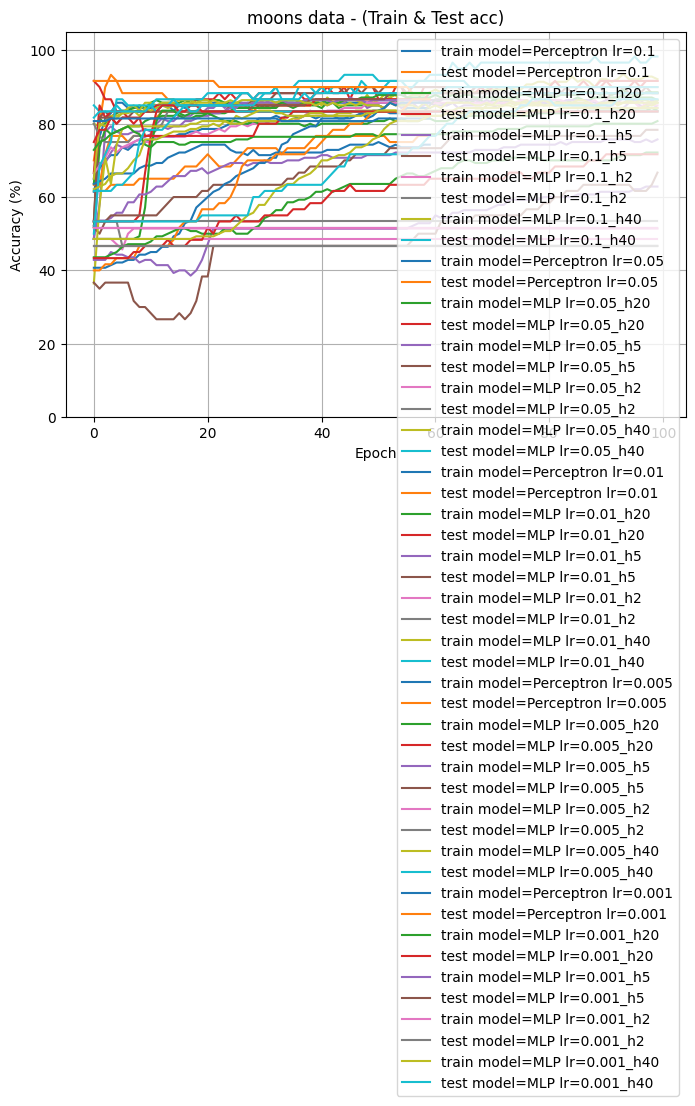

In [10]:
plot_multi_training_curves(
    loss_histories,
    "moons data (Train & Test Loss)",
    "model_comparison"
)    

plot_multi_accuracy_curves(
    acc_histories,
    "moons data - (Train & Test acc)",
    "model_comparison"
)    


ب) مرز تصمیم پرسپترون و MLP (با 5 نرون مخفی) را کنار هم رسم کنید و تفاوت را توضیح دهید.

Epoch 01/100 | Train Loss: 0.5823 Acc: 72.86% | Test Loss: 0.5756 Acc: 75.00%
Epoch 10/100 | Train Loss: 0.5642 Acc: 76.43% | Test Loss: 0.5516 Acc: 78.33%
Epoch 20/100 | Train Loss: 0.5500 Acc: 78.57% | Test Loss: 0.5280 Acc: 83.33%
Epoch 30/100 | Train Loss: 0.5299 Acc: 80.00% | Test Loss: 0.5073 Acc: 85.00%
Epoch 40/100 | Train Loss: 0.5122 Acc: 80.00% | Test Loss: 0.4890 Acc: 85.00%
Epoch 50/100 | Train Loss: 0.5028 Acc: 80.71% | Test Loss: 0.4727 Acc: 86.67%
Epoch 60/100 | Train Loss: 0.4869 Acc: 79.29% | Test Loss: 0.4582 Acc: 85.00%
Epoch 70/100 | Train Loss: 0.4782 Acc: 78.57% | Test Loss: 0.4453 Acc: 86.67%
Epoch 80/100 | Train Loss: 0.4697 Acc: 79.29% | Test Loss: 0.4337 Acc: 86.67%
Epoch 90/100 | Train Loss: 0.4565 Acc: 79.29% | Test Loss: 0.4233 Acc: 88.33%
Epoch 100/100 | Train Loss: 0.4505 Acc: 80.00% | Test Loss: 0.4139 Acc: 88.33%


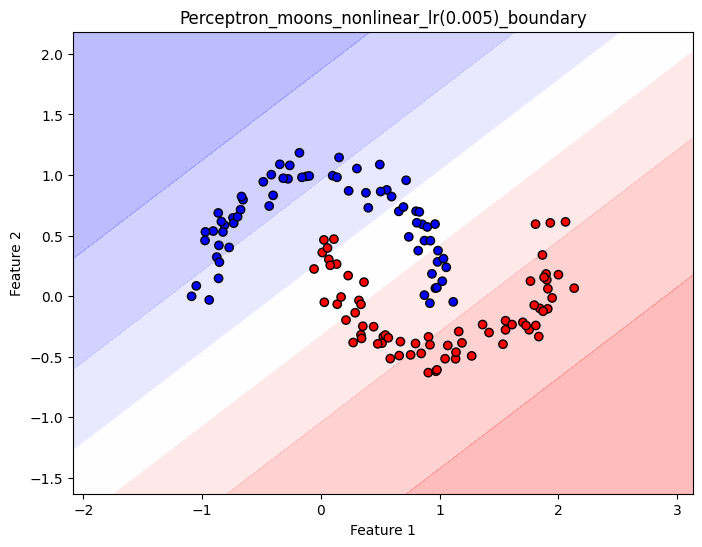

In [12]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=0.005,
		epochs=100,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="moons_nonlinear",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

Epoch 01/100 | Train Loss: 0.7085 Acc: 36.43% | Test Loss: 0.6944 Acc: 48.33%
Epoch 10/100 | Train Loss: 0.4344 Acc: 77.14% | Test Loss: 0.3831 Acc: 83.33%
Epoch 20/100 | Train Loss: 0.3235 Acc: 83.57% | Test Loss: 0.2819 Acc: 85.00%
Epoch 30/100 | Train Loss: 0.2963 Acc: 85.71% | Test Loss: 0.2597 Acc: 86.67%
Epoch 40/100 | Train Loss: 0.2892 Acc: 84.29% | Test Loss: 0.2426 Acc: 88.33%
Epoch 50/100 | Train Loss: 0.2916 Acc: 84.29% | Test Loss: 0.2453 Acc: 88.33%
Epoch 60/100 | Train Loss: 0.2953 Acc: 85.00% | Test Loss: 0.2446 Acc: 88.33%
Epoch 70/100 | Train Loss: 0.2928 Acc: 84.29% | Test Loss: 0.2346 Acc: 88.33%
Epoch 80/100 | Train Loss: 0.2910 Acc: 84.29% | Test Loss: 0.2343 Acc: 88.33%
Epoch 90/100 | Train Loss: 0.2872 Acc: 84.29% | Test Loss: 0.2310 Acc: 90.00%
Epoch 100/100 | Train Loss: 0.2833 Acc: 85.00% | Test Loss: 0.2283 Acc: 90.00%


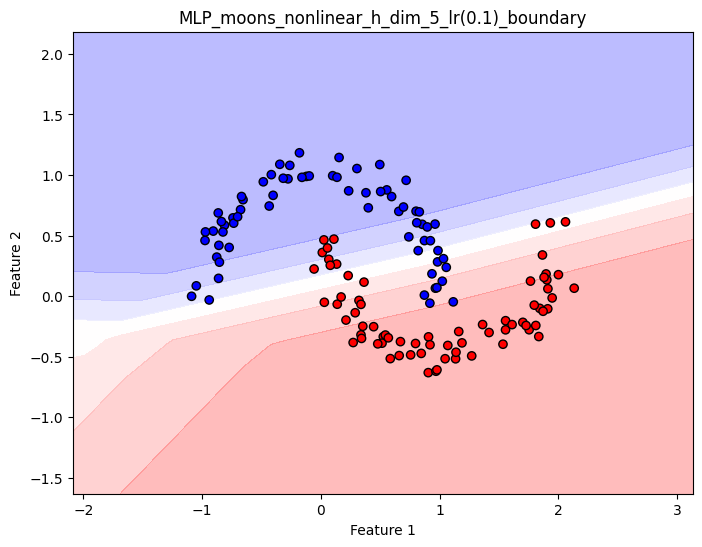

In [13]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

h_dim = 5
result = run_experiment(
	model_class=MLP,
	train_loader=dl_train,
	test_loader=dl_test,
	lr=0.1,
	epochs=100,
	optimizer_name=optimizer[0],
	criterion_name=criterion[0],
	dataset_name=f"moons_nonlinear_h_dim_{h_dim}",
	plot_decision=True,
	X_vis=X_train,
	y_vis=y_train,
	model_kwargs={"hidden_dim": h_dim, "output_dim": 1}
)


3-2-3 مقابله با نویز: به داده ی غیرخطی نویز بیشتری اضافه کنید. (مثلا noise = 0.3 در make_moons)

الف) دقت پرسپترون و MLP (با همان معماری بهینه) چه تغییری میکند؟ کدام مدل مقاوم تر است ؟

Train shape: (140, 2)


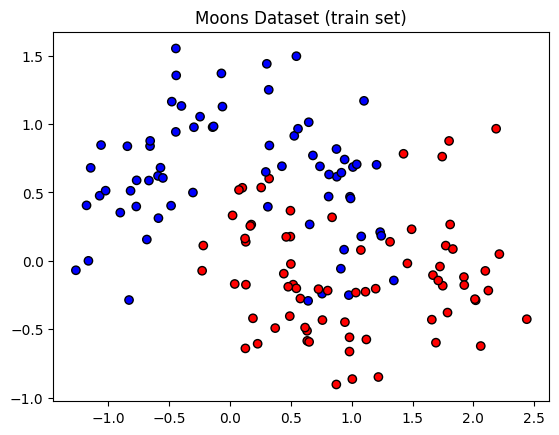

In [14]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_moons_data(noise=0.3)

plot_data(X_train,y_train,"Moons Dataset (train set)")

Epoch 01/100 | Train Loss: 0.7747 Acc: 47.14% | Test Loss: 0.7626 Acc: 50.00%
Epoch 10/100 | Train Loss: 0.7130 Acc: 48.57% | Test Loss: 0.6969 Acc: 53.33%
Epoch 20/100 | Train Loss: 0.6578 Acc: 51.43% | Test Loss: 0.6390 Acc: 55.00%
Epoch 30/100 | Train Loss: 0.6130 Acc: 66.43% | Test Loss: 0.5949 Acc: 70.00%
Epoch 40/100 | Train Loss: 0.5818 Acc: 77.14% | Test Loss: 0.5603 Acc: 80.00%
Epoch 50/100 | Train Loss: 0.5562 Acc: 77.86% | Test Loss: 0.5331 Acc: 78.33%
Epoch 60/100 | Train Loss: 0.5383 Acc: 79.29% | Test Loss: 0.5112 Acc: 81.67%
Epoch 70/100 | Train Loss: 0.5202 Acc: 82.14% | Test Loss: 0.4934 Acc: 83.33%
Epoch 80/100 | Train Loss: 0.5094 Acc: 80.71% | Test Loss: 0.4785 Acc: 83.33%
Epoch 90/100 | Train Loss: 0.4970 Acc: 82.86% | Test Loss: 0.4658 Acc: 83.33%
Epoch 100/100 | Train Loss: 0.4872 Acc: 82.14% | Test Loss: 0.4550 Acc: 83.33%


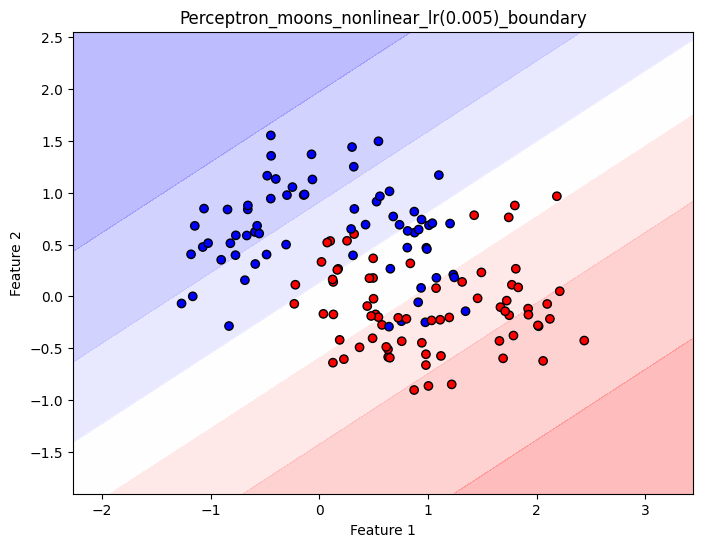

In [15]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=0.005,
		epochs=100,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="moons_nonlinear",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

Epoch 01/200 | Train Loss: 0.6080 Acc: 74.29% | Test Loss: 0.5248 Acc: 83.33%
Epoch 10/200 | Train Loss: 0.3844 Acc: 81.43% | Test Loss: 0.3376 Acc: 83.33%
Epoch 20/200 | Train Loss: 0.3668 Acc: 80.71% | Test Loss: 0.3212 Acc: 85.00%
Epoch 30/200 | Train Loss: 0.3672 Acc: 82.14% | Test Loss: 0.3242 Acc: 83.33%
Epoch 40/200 | Train Loss: 0.3567 Acc: 82.86% | Test Loss: 0.3111 Acc: 83.33%
Epoch 50/200 | Train Loss: 0.3541 Acc: 82.86% | Test Loss: 0.3127 Acc: 83.33%
Epoch 60/200 | Train Loss: 0.3446 Acc: 82.86% | Test Loss: 0.3177 Acc: 83.33%
Epoch 70/200 | Train Loss: 0.3442 Acc: 85.00% | Test Loss: 0.3116 Acc: 83.33%
Epoch 80/200 | Train Loss: 0.3291 Acc: 85.00% | Test Loss: 0.3054 Acc: 85.00%
Epoch 90/200 | Train Loss: 0.3209 Acc: 85.71% | Test Loss: 0.3143 Acc: 83.33%
Epoch 100/200 | Train Loss: 0.3090 Acc: 85.00% | Test Loss: 0.3010 Acc: 85.00%
Epoch 110/200 | Train Loss: 0.3067 Acc: 85.71% | Test Loss: 0.2930 Acc: 86.67%
Epoch 120/200 | Train Loss: 0.3036 Acc: 87.86% | Test Loss: 0.

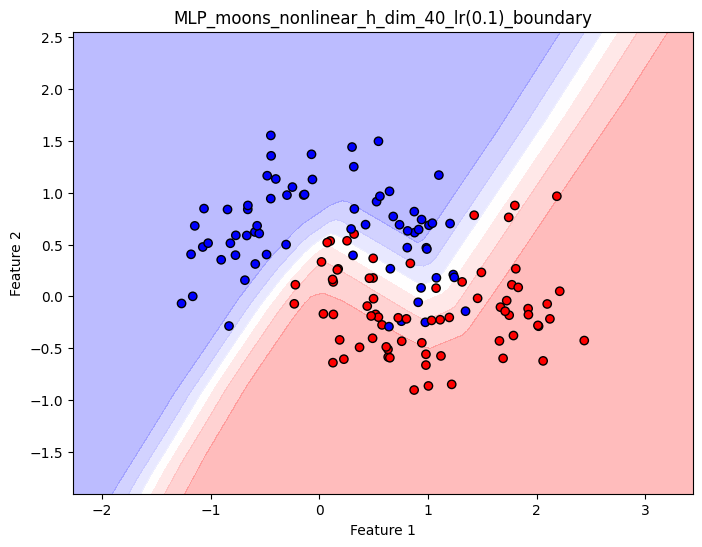

In [17]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

h_dim = 40
result = run_experiment(
	model_class=MLP,
	train_loader=dl_train,
	test_loader=dl_test,
	lr=0.1,
	epochs=200,
	optimizer_name=optimizer[0],
	criterion_name=criterion[0],
	dataset_name=f"moons_nonlinear_h_dim_{h_dim}",
	plot_decision=True,
	X_vis=X_train,
	y_vis=y_train,
	model_kwargs={"hidden_dim": h_dim, "output_dim": 1}
)


3-2-4 مقایسه روی MNIST (دو رقم 0 و 1) – قدرت تعمیم دهی:

الف) ابتداهر دو مدل را روی یک مجموعه آموزش کوچک (مثلا 100 نمونه) و مجموعه آزمون 1000 نمونه آموزش دهید. دقت را بنویسید.

In [5]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_limited_mnist(classes=[0,1],batch_size=32,n_train_samples=100,n_test_sample=1000)

Loaded MNIST classes [0, 1]. Train: 100, Test: 1000


In [9]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=0.005,
		epochs=100,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="limited_mnist_nonlinear",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

Epoch 01/100 | Train Loss: 0.4734 Acc: 83.00% | Test Loss: 0.3069 Acc: 97.50%
Epoch 10/100 | Train Loss: 0.0777 Acc: 100.00% | Test Loss: 0.0701 Acc: 99.50%
Epoch 20/100 | Train Loss: 0.0302 Acc: 100.00% | Test Loss: 0.0438 Acc: 99.50%
Epoch 30/100 | Train Loss: 0.0208 Acc: 100.00% | Test Loss: 0.0340 Acc: 99.60%
Epoch 40/100 | Train Loss: 0.0168 Acc: 100.00% | Test Loss: 0.0285 Acc: 99.60%
Epoch 50/100 | Train Loss: 0.0148 Acc: 100.00% | Test Loss: 0.0248 Acc: 99.60%
Epoch 60/100 | Train Loss: 0.0112 Acc: 100.00% | Test Loss: 0.0231 Acc: 99.60%
Epoch 70/100 | Train Loss: 0.0100 Acc: 100.00% | Test Loss: 0.0202 Acc: 99.70%
Epoch 80/100 | Train Loss: 0.0089 Acc: 100.00% | Test Loss: 0.0186 Acc: 99.80%
Epoch 90/100 | Train Loss: 0.0090 Acc: 100.00% | Test Loss: 0.0171 Acc: 99.80%
Epoch 100/100 | Train Loss: 0.0081 Acc: 100.00% | Test Loss: 0.0162 Acc: 99.80%


In [10]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}

h_dim = 40
result = run_experiment(
	model_class=MLP,
	train_loader=dl_train,
	test_loader=dl_test,
	lr=0.01,
	epochs=100,
	optimizer_name=optimizer[0],
	criterion_name=criterion[0],
	dataset_name=f"limited_mnist_dim_{h_dim}",
	plot_decision=True,
	X_vis=X_train,
	y_vis=y_train,
	model_kwargs={"hidden_dim": h_dim, "output_dim": 1}
)


Epoch 01/100 | Train Loss: 0.6555 Acc: 61.00% | Test Loss: 0.5907 Acc: 89.40%
Epoch 10/100 | Train Loss: 0.1170 Acc: 100.00% | Test Loss: 0.1231 Acc: 99.40%
Epoch 20/100 | Train Loss: 0.0534 Acc: 100.00% | Test Loss: 0.0598 Acc: 99.50%
Epoch 30/100 | Train Loss: 0.0254 Acc: 100.00% | Test Loss: 0.0410 Acc: 99.60%
Epoch 40/100 | Train Loss: 0.0287 Acc: 100.00% | Test Loss: 0.0313 Acc: 99.70%
Epoch 50/100 | Train Loss: 0.0122 Acc: 100.00% | Test Loss: 0.0261 Acc: 99.70%
Epoch 60/100 | Train Loss: 0.0098 Acc: 100.00% | Test Loss: 0.0230 Acc: 99.60%
Epoch 70/100 | Train Loss: 0.0081 Acc: 100.00% | Test Loss: 0.0204 Acc: 99.70%
Epoch 80/100 | Train Loss: 0.0140 Acc: 100.00% | Test Loss: 0.0180 Acc: 99.70%
Epoch 90/100 | Train Loss: 0.0062 Acc: 100.00% | Test Loss: 0.0165 Acc: 99.70%
Epoch 100/100 | Train Loss: 0.0057 Acc: 100.00% | Test Loss: 0.0153 Acc: 99.70%


ب) سپس حجم آموزش را به 1000 نمونه افزایش دهید. دقت آزمون چقدر بهبود میباید ؟ بر هر مدل جدول تعداد نمونه های آموزش در برابر دقت را رسم کنید.

In [11]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_limited_mnist(classes=[0,1],batch_size=32,n_train_samples=1000,n_test_sample=1000)

Loaded MNIST classes [0, 1]. Train: 1000, Test: 1000


In [15]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}
lr= 0.005

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=lr,
		epochs=100,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="limited_mnist_nonlinear",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

loss_histories[f"train model=Perceptron lr={lr}"] = result["train_loss"]
loss_histories[f"test model=Perceptron lr={lr}"] = result["test_loss"]
acc_histories[f"train model=Perceptron lr={lr}"] = result["train_acc"]
acc_histories[f"test model=Perceptron lr={lr}"] = result["test_acc"]

Epoch 01/100 | Train Loss: 0.1737 Acc: 96.50% | Test Loss: 0.0731 Acc: 99.90%
Epoch 10/100 | Train Loss: 0.0145 Acc: 99.80% | Test Loss: 0.0139 Acc: 100.00%
Epoch 20/100 | Train Loss: 0.0096 Acc: 99.80% | Test Loss: 0.0086 Acc: 100.00%
Epoch 30/100 | Train Loss: 0.0074 Acc: 99.90% | Test Loss: 0.0065 Acc: 100.00%
Epoch 40/100 | Train Loss: 0.0077 Acc: 99.90% | Test Loss: 0.0054 Acc: 100.00%
Epoch 50/100 | Train Loss: 0.0051 Acc: 99.90% | Test Loss: 0.0046 Acc: 100.00%
Epoch 60/100 | Train Loss: 0.0044 Acc: 99.90% | Test Loss: 0.0041 Acc: 100.00%
Epoch 70/100 | Train Loss: 0.0038 Acc: 99.90% | Test Loss: 0.0038 Acc: 100.00%
Epoch 80/100 | Train Loss: 0.0034 Acc: 99.90% | Test Loss: 0.0035 Acc: 100.00%
Epoch 90/100 | Train Loss: 0.0030 Acc: 99.90% | Test Loss: 0.0033 Acc: 100.00%
Epoch 100/100 | Train Loss: 0.0027 Acc: 99.90% | Test Loss: 0.0031 Acc: 100.00%


In [16]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}
lr=0.01

h_dim = 40
result = run_experiment(
	model_class=MLP,
	train_loader=dl_train,
	test_loader=dl_test,
	lr=lr,
	epochs=100,
	optimizer_name=optimizer[0],
	criterion_name=criterion[0],
	dataset_name=f"limited_mnist_dim_{h_dim}",
	plot_decision=True,
	X_vis=X_train,
	y_vis=y_train,
	model_kwargs={"hidden_dim": h_dim, "output_dim": 1}
)

loss_histories[f"train model=MLP lr={lr}_h{h_dim}"] = result["train_loss"]
loss_histories[f"test model=MLP lr={lr}_h{h_dim}"] = result["test_loss"]
acc_histories[f"train model=MLP lr={lr}_h{h_dim}"] = result["train_acc"]
acc_histories[f"test model=MLP lr={lr}_h{h_dim}"] = result["test_acc"]

Epoch 01/100 | Train Loss: 0.3210 Acc: 95.30% | Test Loss: 0.1636 Acc: 99.50%
Epoch 10/100 | Train Loss: 0.0140 Acc: 99.80% | Test Loss: 0.0131 Acc: 100.00%
Epoch 20/100 | Train Loss: 0.0077 Acc: 99.80% | Test Loss: 0.0065 Acc: 100.00%
Epoch 30/100 | Train Loss: 0.0052 Acc: 99.90% | Test Loss: 0.0044 Acc: 100.00%
Epoch 40/100 | Train Loss: 0.0037 Acc: 99.90% | Test Loss: 0.0033 Acc: 100.00%
Epoch 50/100 | Train Loss: 0.0027 Acc: 99.90% | Test Loss: 0.0028 Acc: 100.00%
Epoch 60/100 | Train Loss: 0.0021 Acc: 100.00% | Test Loss: 0.0023 Acc: 100.00%
Epoch 70/100 | Train Loss: 0.0017 Acc: 100.00% | Test Loss: 0.0020 Acc: 100.00%
Epoch 80/100 | Train Loss: 0.0014 Acc: 100.00% | Test Loss: 0.0017 Acc: 100.00%
Epoch 90/100 | Train Loss: 0.0012 Acc: 100.00% | Test Loss: 0.0015 Acc: 100.00%
Epoch 100/100 | Train Loss: 0.0011 Acc: 100.00% | Test Loss: 0.0014 Acc: 100.00%


In [18]:
import pandas as pd

data = {
    "Training Samples": [100, 1000],
    "Perceptron Test Accuracy (%)": [99.8, 99.9],
    "Perceptron Train Accuracy (%)": [100, 100],
    "MLP Test Accuracy (%)": [99.7, 100],
    "MLP Train Accuracy (%)": [100, 100],
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

 Training Samples  Perceptron Test Accuracy (%)  Perceptron Train Accuracy (%)  MLP Test Accuracy (%)  MLP Train Accuracy (%)
              100                          99.8                            100                   99.7                     100
             1000                          99.9                            100                  100.0                     100


3-2-5 تحلیل عملکرد پرسپترون روی MNIST :

الف) توﺿﻴﺢ ﺩﻫﻴﺪ ﭼﺮﺍ ﭘﺮﺳﭙﺘﺮﻭﻥ (ﺣﺘﻲ ﺑﺎ ﻭﺟﻮﺩ ﺧﻄﻲ ﻧﺒﻮﺩﻥ ﺩﺍﺩﻩ) ﻣﻤﻜﻦ ﺍﺳﺖ ﺭﻭﻱ MNIST ﺑﺎ ﺩﻭ ﺭﻗﻢ ۰ ﻭ ۱ ﺩﻗﺖ ﺑﺎﻻﻳﻲ ﺑﺪﻫﺪ. ﺁﻳﺎ ﻣﻲ ﺗﻮﺍﻧﻴﺪ ﻳﻚ ﻧﻘﺺ ﺩﺭ ﺍﻧﺘﺨﺎﺏ ﺍﻳﻦ ﺩﻭ ﺭﻗﻢ ﺧﺎﺹ ﭘﻴﺪﺍ ﻛﻨﻴﺪ؟ (ﺭﺍﻫﻨﻤﺎﻳﻲ: ﺗﺼﺎﻭﻳﺮ ﺭﻗﻢ ۰ ﻭ ۱ ﺭ ﺍﺑﺒﻴﻨﻴﺪ -ﺁﻳﺎ ﺍﺯ ﻧﻈﺮ ﭘﻴﻜﺴﻞ ﻫﺎﻱ ﺭﻭﺷﻦ ﺗﻔﺎﻭﺕ ﻭﺍﺿﺤﻲ ﺩﺍﺭﻧﺪ؟)

ب) میتوانید زوج رقم دیگری را پیشنهاد کنید که این اتفاق روی پرسپترون برای آنها نیفتد؟

✅ بارگذاری کلاس‌های [3, 8]. تعداد نمونه‌های آموزش: 11982
   برچسب‌های منحصربه‌فرد: [0 1]


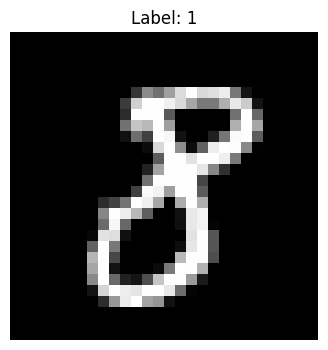

In [2]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_normalized_mnist(classes=[3,8],batch_size=32)

show_random_image(X_train, y_train)

In [3]:
y_test

array([0, 0, 0, ..., 0, 1, 0], dtype=int64)

In [ ]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}
lr= 0.005

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=lr,
		epochs=100,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="mnist_3_8",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

loss_histories[f"train model=Perceptron lr={lr}"] = result["train_loss"]
loss_histories[f"test model=Perceptron lr={lr}"] = result["test_loss"]
acc_histories[f"train model=Perceptron lr={lr}"] = result["train_acc"]
acc_histories[f"test model=Perceptron lr={lr}"] = result["test_acc"]

Epoch 01/100 | Train Loss: 0.2006 Acc: 93.80% | Test Loss: 0.1262 Acc: 96.37%
Epoch 10/100 | Train Loss: 0.1016 Acc: 97.02% | Test Loss: 0.1004 Acc: 96.72%
Epoch 20/100 | Train Loss: 0.0961 Acc: 97.17% | Test Loss: 0.0981 Acc: 96.82%
Epoch 30/100 | Train Loss: 0.0932 Acc: 97.20% | Test Loss: 0.0992 Acc: 96.77%
Epoch 40/100 | Train Loss: 0.0919 Acc: 97.28% | Test Loss: 0.0976 Acc: 96.82%
Epoch 50/100 | Train Loss: 0.0899 Acc: 97.39% | Test Loss: 0.0987 Acc: 96.77%
Epoch 60/100 | Train Loss: 0.0888 Acc: 97.36% | Test Loss: 0.0973 Acc: 96.93%
Epoch 70/100 | Train Loss: 0.0881 Acc: 97.44% | Test Loss: 0.0978 Acc: 96.82%
Epoch 80/100 | Train Loss: 0.0873 Acc: 97.44% | Test Loss: 0.0973 Acc: 96.82%
Epoch 90/100 | Train Loss: 0.0867 Acc: 97.49% | Test Loss: 0.0976 Acc: 96.77%
Epoch 100/100 | Train Loss: 0.0859 Acc: 97.50% | Test Loss: 0.0976 Acc: 96.98%


✅ بارگذاری کلاس‌های [4, 9]. تعداد نمونه‌های آموزش: 11791
   برچسب‌های منحصربه‌فرد: [0 1]


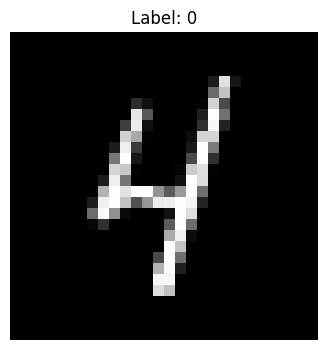

In [5]:
X_train, X_test, y_train, y_test, dl_train, dl_test = get_normalized_mnist(classes=[4,9],batch_size=32)

show_random_image(X_train, y_train)

In [ ]:
criterion = ["BCEWithLogitsLoss", "BCELoss", "CrossEntropyLoss"]
optimizer = ["SGD", "Adam"]
loss_histories = {}
acc_histories = {}
lr= 0.005

result = run_experiment(
		model_class=Perceptron,
		train_loader=dl_train,
		test_loader=dl_test,
		lr=lr,
		epochs=50,
		optimizer_name=optimizer[0],
		criterion_name=criterion[0],
		dataset_name="mnist_4_9",
		plot_decision=True,
		X_vis=X_train,
		y_vis=y_train,
		model_kwargs={}
	)

loss_histories[f"train model=Perceptron lr={lr}"] = result["train_loss"]
loss_histories[f"test model=Perceptron lr={lr}"] = result["test_loss"]
acc_histories[f"train model=Perceptron lr={lr}"] = result["train_acc"]
acc_histories[f"test model=Perceptron lr={lr}"] = result["test_acc"]

Epoch 01/50 | Train Loss: 0.2503 Acc: 92.32% | Test Loss: 0.1565 Acc: 95.63%
Epoch 10/50 | Train Loss: 0.1010 Acc: 96.64% | Test Loss: 0.0956 Acc: 96.94%
Epoch 20/50 | Train Loss: 0.0909 Acc: 96.99% | Test Loss: 0.0889 Acc: 96.84%
Epoch 30/50 | Train Loss: 0.0864 Acc: 97.19% | Test Loss: 0.0865 Acc: 96.89%
Epoch 40/50 | Train Loss: 0.0833 Acc: 97.27% | Test Loss: 0.0855 Acc: 96.94%
Epoch 50/50 | Train Loss: 0.0812 Acc: 97.28% | Test Loss: 0.0866 Acc: 96.99%
